# Preparations

In [1]:
#%pip install matplotlib-venn
#%pip install fastparquet
#%pip install tqdm
#%pip install cartopy
#%pip install rasterio

In [1]:
import os
import pandas as pd
from tqdm import tqdm
import glob
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from matplotlib_venn import venn3
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import rasterio 
import numpy as np
from fastparquet import ParquetFile


os.chdir ('C:\\Users\\hamod4691\\Code\\arctic-benthic-biodiversity\\GBIF')

In [2]:
os.getcwd()

'C:\\Users\\hamod4691\\Code\\arctic-benthic-biodiversity\\GBIF'

## Background checks

Check column names and coverages

Eurasia

In [3]:
# Load the file into a DataFrame
# Assuming the file is tab-separated
file_path = "filtered_data_eurasia.txt"
df = pd.read_csv(file_path, sep="\t", low_memory=False)
# Calculate the percentage of non-missing values for each column
coverage = df.notnull().mean() * 100
# Convert to a DataFrame for better readability
coverage_df = coverage.reset_index()
coverage_df.columns = ['Column', 'Coverage (%)']
# Sort by coverage percentage (optional)
coverage_df = coverage_df.sort_values(by='Coverage (%)', ascending=False)
# Print the result
print(coverage_df)
# Save the coverage percentages to a file (optional)
coverage_df.to_csv("column_coverage_percentages_eurasia.csv", index=False)

              Column  Coverage (%)
0             gbifID         100.0
4            license         100.0
17     basisOfRecord         100.0
6          publisher         100.0
97   decimalLatitude         100.0
..               ...           ...
199   superfamilyKey           0.0
205      subgenusKey           0.0
202         tribeKey           0.0
203      subtribeKey           0.0
214       isInvasive           0.0

[230 rows x 2 columns]


US

In [4]:
# Load the file into a DataFrame
# Assuming the file is tab-separated
file_path = "filtered_data_US.txt"
df = pd.read_csv(file_path, sep="\t", low_memory=False)
# Calculate the percentage of non-missing values for each column
coverage = df.notnull().mean() * 100
# Convert to a DataFrame for better readability
coverage_df = coverage.reset_index()
coverage_df.columns = ['Column', 'Coverage (%)']
# Sort by coverage percentage (optional)
coverage_df = coverage_df.sort_values(by='Coverage (%)', ascending=False)
# Print the result
print(coverage_df)
# Save the coverage percentages to a file (optional)
coverage_df.to_csv("column_coverage_percentages_US.csv", index=False)

              Column  Coverage (%)
0             gbifID         100.0
4            license         100.0
17     basisOfRecord         100.0
6          publisher         100.0
97   decimalLatitude         100.0
..               ...           ...
199   superfamilyKey           0.0
205      subgenusKey           0.0
202         tribeKey           0.0
203      subtribeKey           0.0
214       isInvasive           0.0

[230 rows x 2 columns]


Check the column contents

In [5]:
# Replace 'filtered_data_eurasia.txt' with the path to your tab-delimited file
input_file_path = 'filtered_data_eurasia.txt'
# Specify the columns you want to extract
columns_to_extract = ['basisOfRecord', 'bibliographicCitation', 'habitat']
# Number of samples to extract
num_samples = 10
# Read the file in chunks to handle large files efficiently
# Use only the specified columns and set dtype to str
try:
    # Read the file using pandas
    df = pd.read_csv(
        input_file_path,
        delimiter='\t',
        usecols=columns_to_extract,
        dtype=str,  # Treat all columns as strings
        low_memory=False  # Avoid memory optimization warnings
    )
    
    # Extract a sample of 10 rows from the specified columns
    sample_data = df.sample(n=num_samples, random_state=42)  # Random seed for reproducibility
    
    # Print the sample data to the console
    print("Sample Data:")
    print(sample_data.to_string(index=False))  # Print without the index for cleaner output
except ValueError as e:
    print(f"Error: {e}. Please check if the specified columns exist in the file.")

Sample Data:
bibliographicCitation      basisOfRecord habitat
                  NaN  HUMAN_OBSERVATION     NaN
                  NaN  HUMAN_OBSERVATION     NaN
                  NaN  HUMAN_OBSERVATION     NaN
                  NaN PRESERVED_SPECIMEN     NaN
                  NaN  HUMAN_OBSERVATION     NaN
                  NaN PRESERVED_SPECIMEN     NaN
                  NaN    MATERIAL_SAMPLE     NaN
                  NaN  HUMAN_OBSERVATION     NaN
                  NaN  HUMAN_OBSERVATION     NaN
                  NaN         OCCURRENCE     NaN


In [6]:
# Replace 'filtered_data_eurasia.txt' with the path to your tab-delimited file
input_file_path = 'filtered_data_US.txt'
# Specify the columns you want to extract
columns_to_extract = ['acceptedNameUsage', 'scientificName', 'publisher', 'protocol']
# Number of samples to extract
num_samples = 10
# Read the file in chunks to handle large files efficiently
# Use only the specified columns and set dtype to str
try:
    # Read the file using pandas
    df = pd.read_csv(
        input_file_path,
        delimiter='\t',
        usecols=columns_to_extract,
        dtype=str,  # Treat all columns as strings
        low_memory=False  # Avoid memory optimization warnings
    )
    
    # Extract a sample of 10 rows from the specified columns
    sample_data = df.sample(n=num_samples, random_state=42)  # Random seed for reproducibility
    
    # Print the sample data to the console
    print("Sample Data:")
    print(sample_data.to_string(index=False))  # Print without the index for cleaner output
except ValueError as e:
    print(f"Error: {e}. Please check if the specified columns exist in the file.")

Sample Data:
                                                  publisher                                      scientificName acceptedNameUsage protocol
                            United States Geological Survey      Semisuberites cribrosa (Miklucho-Maclay, 1870)               NaN      EML
                                  Canadian Museum of Nature                      Lebbeus polaris (Sabine, 1824)               NaN      EML
                            United States Geological Survey      Paragorgia arborea var. pacifica Verrill, 1922               NaN      EML
                   University of Alaska Museum of the North                                            Chordata               NaN      EML
National Museum of Natural History, Smithsonian Institution Coelosphaera oglalai Lehnert, Stone & Heimler, 2006               NaN      EML
                                  Canadian Museum of Nature                Calathura brachiata (Stimpson, 1853)               NaN      EML
              

# Merge into one parquet file

In [7]:
# Inputs (adjust paths if needed)
east_occ_file = "filtered_data_eurasia.txt"
west_occ_file = "filtered_data_US.txt"
# Output directories
shards_dir_east = "occ_parquet_shards_east"
shards_dir_west = "occ_parquet_shards_west"
filt_dir_east = "occ_filtered_marine_east"
filt_dir_west = "occ_filtered_marine_west"
# Create output directories
os.makedirs(shards_dir_east, exist_ok=True)
os.makedirs(shards_dir_west, exist_ok=True)
# Print confirmation
print(east_occ_file)
print(west_occ_file)
print("Setup complete")

filtered_data_eurasia.txt
filtered_data_US.txt
Setup complete


In [8]:
chunksize_rows = 500000  # Process in chunks of 500,000 rows
# Define the columns you need
needed_cols = [
    "gbifID",
    "datasetKey",
    "decimalLatitude", 
    "decimalLongitude", 
    "coordinatePrecision",
    "coordinateUncertaintyInMeters",
    "hasGeospatialIssues",
    "verbatimCoordinateSystem",
    "verbatimSRS",
    "depth",
    "depthAccuracy",
    "eventID", 
    "eventDate",
    "eventRemarks",
    "startDayOfYear", 
    "endDayOfYear",     
    "year",
    "verbatimScientificName", 
    "acceptedScientificName",
    "identificationQualifier", 
    "lifeStage", 
    "sex",
    "taxonomicStatus",
    "taxonomicIssue",
    "taxonRank", 
    "phylum",
    "class",
    "order",
    "family",
    "genus",
    "taxonKey", 
    "acceptedTaxonKey", 
    "phylumKey", 
    "classKey", 
    "orderKey", 
    "familyKey", 
    "genusKey", 
    "individualCount", 
    "organismQuantity", 
    "organismQuantityType", 
    "occurrenceStatus",
    "occurrenceRemarks", 
    "basisOfRecord",
    "dynamicProperties",
    "samplingProtocol", 
    "sampleSizeValue", 
    "sampleSizeUnit", 
    "samplingEffort",     
    "preparations",    
    "recordedBy", 
    "isSequenced",
    "habitat", 
    "locality",   
    "locationRemarks",
    "waterBody",
    "publisher", 
    "publishingCountry", 
    "datasetName",
    "bibliographicCitation",    
    "license", 
    "accessRights", 
    "rightsHolder", 
    "modified",
    "lastCrawled", 
    "issue"
]
# Initialize shard counter
shard_count_east = 0
if east_occ_file is not None and os.path.isfile(east_occ_file):
    # Read the file in chunks, keeping only the necessary columns
    reader = pd.read_csv(
        east_occ_file,
        sep="\t",
        usecols=lambda c: c in set(needed_cols),  # Keep only needed columns
        dtype=str,
        chunksize=chunksize_rows,
        low_memory=False,
        quoting=3
    )
    for i, chunk in enumerate(tqdm(reader, desc="Sharding East Occurrence Data")):
        # Save each chunk as a Parquet file
        out_path = os.path.join(shards_dir_east, f"east_shard_{str(i).zfill(5)}.parquet")
        chunk.to_parquet(out_path, index=False, compression="zstd")
        shard_count_east += 1
        print(out_path)
else:
    print("East occurrence file not found")
print(f"Total shards created: {shard_count_east}")
print("Sharding complete")

Sharding East Occurrence Data: 1it [00:09,  9.51s/it]

occ_parquet_shards_east\east_shard_00000.parquet


Sharding East Occurrence Data: 2it [00:18,  9.31s/it]

occ_parquet_shards_east\east_shard_00001.parquet


Sharding East Occurrence Data: 3it [00:29,  9.78s/it]

occ_parquet_shards_east\east_shard_00002.parquet


... (2 outputs left out)

Sharding East Occurrence Data: 5it [00:47,  9.55s/it]

occ_parquet_shards_east\east_shard_00004.parquet


Sharding East Occurrence Data: 6it [00:56,  9.50s/it]

occ_parquet_shards_east\east_shard_00005.parquet
Total shards created: 6
Sharding complete


In [9]:
chunksize_rows = 500000  # Process in chunks of 500,000 rows
# Define the columns you need
needed_cols = [
    "gbifID",
    "datasetKey",
    "decimalLatitude", 
    "decimalLongitude", 
    "coordinatePrecision",
    "coordinateUncertaintyInMeters",
    "hasGeospatialIssues",
    "verbatimCoordinateSystem",
    "verbatimSRS",
    "depth",
    "depthAccuracy",
    "eventID", 
    "eventDate",
    "eventRemarks",
    "startDayOfYear", 
    "endDayOfYear",     
    "year",
    "verbatimScientificName", 
    "acceptedScientificName",
    "identificationQualifier", 
    "lifeStage", 
    "sex",
    "taxonomicStatus",
    "taxonomicIssue",
    "taxonRank", 
    "phylum",
    "class",
    "order",
    "family",
    "genus",
    "taxonKey", 
    "acceptedTaxonKey", 
    "phylumKey", 
    "classKey", 
    "orderKey", 
    "familyKey", 
    "genusKey", 
    "individualCount", 
    "organismQuantity", 
    "organismQuantityType", 
    "occurrenceStatus",
    "occurrenceRemarks", 
    "basisOfRecord",
    "dynamicProperties",
    "samplingProtocol", 
    "sampleSizeValue", 
    "sampleSizeUnit", 
    "samplingEffort",     
    "preparations",    
    "recordedBy", 
    "isSequenced",
    "habitat", 
    "locality",   
    "locationRemarks",
    "waterBody",
    "publisher", 
    "publishingCountry", 
    "datasetName",
    "bibliographicCitation",    
    "license", 
    "accessRights", 
    "rightsHolder", 
    "modified",
    "lastCrawled", 
    "issue"
]
# Initialize shard counter
shard_count_west = 0
if west_occ_file is not None and os.path.isfile(west_occ_file):
    # Read the file in chunks, keeping only the necessary columns
    reader = pd.read_csv(
        west_occ_file,
        sep="\t",
        usecols=lambda c: c in set(needed_cols),  # Keep only needed columns
        dtype=str,
        chunksize=chunksize_rows,
        low_memory=False,
        quoting=3
    )
    for i, chunk in enumerate(tqdm(reader, desc="Sharding West Occurrence Data")):
        # Save each chunk as a Parquet file
        out_path = os.path.join(shards_dir_west, f"west_shard_{str(i).zfill(5)}.parquet")
        chunk.to_parquet(out_path, index=False, compression="zstd")
        shard_count_west += 1
        print(out_path)
else:
    print("West occurrence file not found")
print(f"Total shards created: {shard_count_west}")
print("Sharding complete")

Sharding West Occurrence Data: 1it [00:08,  8.05s/it]

occ_parquet_shards_west\west_shard_00000.parquet
Total shards created: 1
Sharding complete


In [10]:
# Directories containing the Parquet shards
shards_dir_east = "occ_parquet_shards_east"
shards_dir_west = "occ_parquet_shards_west"
# Output file names
final_out_parquet = "gbif_combined_dataset.parquet"
final_out_head = "gbif_combined_dataset_head.csv"
# Locate all Parquet files in the east and west directories
east_shards = sorted(glob.glob(os.path.join(shards_dir_east, "*.parquet")))
west_shards = sorted(glob.glob(os.path.join(shards_dir_west, "*.parquet")))
all_shards = east_shards + west_shards  # Combine east and west shards
# Combine all Parquet files into a single DataFrame
frames = []
for shard in tqdm(all_shards, desc="Combining Parquet Shards"):
    frames.append(pd.read_parquet(shard))
if len(frames) > 0:
    # Concatenate all DataFrames
    final_df = pd.concat(frames, ignore_index=True)
    
    # Save the combined dataset as a Parquet file
    final_df.to_parquet(final_out_parquet, index=False, compression="zstd")
    
    # Save the first 25 rows as a CSV preview
    final_df.head(25).to_csv(final_out_head, index=False)
    
    # Print output details
    print(f"Final Parquet file saved: {final_out_parquet}")
    print(f"CSV preview saved: {final_out_head}")
    print(f"Total records in final dataset: {len(final_df)}")
else:
    print("No Parquet shards found in the specified directories.")
print("Dataset combination complete.")

Combining Parquet Shards: 100%|██████████| 8/8 [00:01<00:00,  6.84it/s]


Final Parquet file saved: gbif_combined_dataset.parquet
CSV preview saved: gbif_combined_dataset_head.csv
Total records in final dataset: 3402288
Dataset combination complete.


# Small fixes

Remove ""

In [11]:
# Load the Parquet file
file_path = "gbif_combined_dataset.parquet"
df = pd.read_parquet(file_path)
# Replace empty strings with NA
df = df.replace('""', pd.NA)
# Save the updated DataFrame back to a Parquet file
df.to_parquet("gbif_combined_dataset.parquet", index=False)

Check column types

In [12]:
# Load the Parquet file
file_path = "gbif_combined_dataset.parquet"
df = pd.read_parquet(file_path)
# Display basic information about the dataset
print(f"Number of rows: {len(df)}")
print(f"Number of columns: {len(df.columns)}")
# Display column names and data types
print("Column names and data types:")
print(df.dtypes)

Number of rows: 3402288
Number of columns: 65
Column names and data types:
gbifID                    str
accessRights              str
bibliographicCitation     str
license                   str
modified                  str
                         ... 
genusKey                  str
acceptedScientificName    str
verbatimScientificName    str
lastCrawled               str
isSequenced               str
Length: 65, dtype: object


Change column types

In [13]:
# Load the Parquet file into a DataFrame
df = pd.read_parquet("gbif_combined_dataset.parquet")
# Define the column data types
column_types = {
    "gbifID": "string",
    "datasetKey": "string",
    "decimalLatitude": "float64",
    "decimalLongitude": "float64",
    "coordinatePrecision": "float64",
    "coordinateUncertaintyInMeters": "float64",
    "hasGeospatialIssues": "string",
    "verbatimCoordinateSystem": "string",
    "verbatimSRS": "string",
    "depth": "float64",
    "depthAccuracy": "float64",
    "eventID": "string",
    "eventDate": "string",
    "eventRemarks": "string",
    "startDayOfYear": "string",
    "endDayOfYear": "string",
    "year": "string",
    "verbatimScientificName": "string",
    "acceptedScientificName": "string",
    "identificationQualifier": "string",
    "lifeStage": "string",
    "sex": "string",
    "taxonomicStatus": "string",
    "taxonomicIssue": "string",
    "taxonRank": "string",
    "phylum": "string",
    "class": "string",
    "order": "string",
    "family": "string",
    "genus": "string",
    "taxonKey": "Int64",
    "acceptedTaxonKey": "Int64",
    "phylumKey": "Int64",
    "classKey": "Int64",
    "orderKey": "Int64",
    "familyKey": "Int64",
    "genusKey": "Int64",
    "individualCount": "Int64",
    "organismQuantity": "string",
    "organismQuantityType": "string",
    "occurrenceStatus": "string",
    "occurrenceRemarks": "string",
    "basisOfRecord": "string",
    "dynamicProperties": "string",
    "samplingProtocol": "string",  
    "sampleSizeValue": "string",
    "sampleSizeUnit": "string",
    "samplingEffort": "string",
    "preparations": "string",
    "recordedBy": "string",  
    "isSequenced": "string",
    "habitat": "string",
    "locality": "string",
    "locationRemarks": "string",
    "waterBody": "string",
    "publisher": "string",
    "publishingCountry": "string",
    "datasetName": "string",
    "bibliographicCitation": "string",
    "license": "string",
    "accessRights": "string",
    "rightsHolder": "string",
    "modified": "datetime64[ns]",  # ISO 8601 Date
    "lastCrawled": "datetime64[ns]",  # ISO 8601 Date
    "issue": "string",  
}
# Cast the columns to their respective data types
for column, dtype in column_types.items():
    if column in df.columns:
        if dtype == "string":
            df[column] = df[column].astype("string")
        elif dtype == "boolean":
            df[column] = df[column].astype("boolean")
        elif dtype == "float64":
            df[column] = pd.to_numeric(df[column], errors="coerce")
        elif dtype == "Int64":  # Nullable integer type
            df[column] = pd.to_numeric(df[column], errors="coerce").astype("Int64")
        elif dtype == "datetime64[ns]":
            df[column] = pd.to_datetime(df[column], errors="coerce")
        else:
            df[column] = df[column].astype(dtype)

# Ensure the DataFrame columns are in the desired order
desired_column_order = list(column_types.keys())
df = df[desired_column_order]
# Save the updated DataFrame back to a Parquet file
df.to_parquet("gbif_combined_dataset.parquet", index=False)

# Data cleaning

## Filter out stations on land based on bathymetry

In [14]:
# Filter at the level of station

In [15]:
# Step 1: Load the Parquet file
input_file = "gbif_combined_dataset.parquet"
df = pd.read_parquet(input_file)
# Step 2: Extract unique station locations
unique_stations = df[['decimalLatitude', 'decimalLongitude']].drop_duplicates()
# Step 3: Save the result to a new file
output_file = "unique_coordinates.parquet"
unique_stations.to_parquet(output_file, index=False)
# Optional: Save as CSV if needed
unique_stations.to_csv("unique_coordinates.csv", index=False)
print(f"Unique station locations saved to {output_file}")

Unique station locations saved to unique_coordinates.parquet


In [16]:
# Extract raster values

In [17]:
def extract_raster_values(raster_path, coordinates_df, batch_size=10000):
    """
    Extract raster values for given coordinates from a single raster file.
    Parameters:
        raster_path (str): Path to the merged raster file.
        coordinates_df (pd.DataFrame): DataFrame with 'decimalLatitude' and 'decimalLongitude'.
        batch_size (int): Number of points to process in each batch.
    Returns:
        pd.DataFrame: DataFrame with extracted raster values.
    """
    results = []
    total_batches = len(coordinates_df) // batch_size + (1 if len(coordinates_df) % batch_size != 0 else 0)
    with rasterio.open(raster_path) as src:
        bounds = src.bounds  # Get raster bounds
        with tqdm(total=total_batches, desc="Processing Batches", unit="batch") as pbar:
            for i in range(0, len(coordinates_df), batch_size):
                batch = coordinates_df.iloc[i:i + batch_size].copy()
                batch.loc[:, 'gebco'] = np.nan  # Initialize the column for raster values
                # Adjust longitudes at the antimeridian
                batch['decimalLongitude'] = batch['decimalLongitude'].apply(
                    lambda lon: -180 if lon == 180 else lon
                )
                # Filter coordinates within the raster bounds
                batch_in_bounds = batch[
                    (batch['decimalLongitude'] >= bounds.left) &
                    (batch['decimalLongitude'] <= bounds.right) &
                    (batch['decimalLatitude'] >= bounds.bottom) &
                    (batch['decimalLatitude'] <= bounds.top)
                ]
                # Extract raster values for these coordinates
                coords = [(lon, lat) for lon, lat in zip(batch_in_bounds['decimalLongitude'], batch_in_bounds['decimalLatitude'])]
                values = list(src.sample(coords))
                # Assign values to the batch DataFrame
                for idx, value in zip(batch_in_bounds.index, values):
                    if value[0] is not None and not np.isnan(value[0]):
                        batch.loc[idx, 'gebco'] = value[0]
                results.append(batch)
                pbar.update(1)
    return pd.concat(results, ignore_index=True)
# File path to the merged raster
raster_file = "../GEBCO/gebco_merged.tif"
# Load the unique_coordinates.parquet file
coordinates = pd.read_parquet("unique_coordinates.parquet")
# Ensure decimalLongitude and decimalLatitude are numeric
coordinates['decimalLongitude'] = pd.to_numeric(coordinates['decimalLongitude'], errors='coerce')
coordinates['decimalLatitude'] = pd.to_numeric(coordinates['decimalLatitude'], errors='coerce')
# Drop rows with invalid (NaN) coordinates
coordinates = coordinates.dropna(subset=['decimalLongitude', 'decimalLatitude'])
# Extract raster values
result_df = extract_raster_values(raster_file, coordinates)
# Save the results to a Parquet file
result_df.to_parquet("gebco_values.parquet", index=False)
# Save the results to a CSV file
result_df.to_csv("gebco_values.csv", index=False)
print("Results saved as 'gebco_values.parquet' and 'gebco_values.csv'.")

Processing Batches: 100%|██████████| 20/20 [00:17<00:00,  1.14batch/s]


Results saved as 'gebco_values.parquet' and 'gebco_values.csv'.


Apply filter (remove records above zero)

In [18]:
# Load the Parquet file
coordinates = pd.read_parquet("gebco_values.parquet")
# Filter out stations with 'gebco' values above zero
filtered_coordinates = coordinates[coordinates['gebco'] <= 0]
# Save the filtered DataFrame to a new Parquet file
filtered_coordinates.to_parquet("gebco_filtered.parquet", index=False)
# Save the filtered DataFrame to a new CSV file
filtered_coordinates.to_csv("gebco_filtered.csv", index=False)
print("Filtered results saved as 'gebco_filtered.parquet' and 'gebco_filtered.csv'.")

Filtered results saved as 'gebco_filtered.parquet' and 'gebco_filtered.csv'.


In [19]:
# File paths
filtered_coordinates_file = "gebco_filtered.parquet"
gbif_file = "gbif_combined_dataset.parquet"
output_file = "gbif_filtered_dataset.parquet"
# Load the filtered coordinates (from gebco_values_filtered.parquet)
filtered_coordinates = pd.read_parquet(filtered_coordinates_file)
# Extract unique coordinate pairs and their corresponding 'gebco' values
filtered_coords_with_gebco = filtered_coordinates[['decimalLongitude', 'decimalLatitude', 'gebco']]
# Convert to a set for fast filtering
filtered_coords_set = set(zip(filtered_coords_with_gebco['decimalLongitude'], filtered_coords_with_gebco['decimalLatitude']))
# Define a function to filter a chunk and add the 'gebcoDepth' column
def filter_and_add_gebco(chunk, coords_with_gebco):
    """
    Filter a chunk of the GBIF dataset and add the 'gebcoDepth' column.
    Parameters:
        chunk (pd.DataFrame): A chunk of the GBIF dataset.
        coords_with_gebco (pd.DataFrame): DataFrame with 'decimalLongitude', 'decimalLatitude', and 'gebco'.
    Returns:
        pd.DataFrame: The filtered chunk with the 'gebcoDepth' column added.
    """
    # Convert 'decimalLongitude' and 'decimalLatitude' to numeric (float64) in the chunk
    chunk['decimalLongitude'] = pd.to_numeric(chunk['decimalLongitude'], errors='coerce')
    chunk['decimalLatitude'] = pd.to_numeric(chunk['decimalLatitude'], errors='coerce')
    # Create a tuple of (longitude, latitude) for each row in the chunk
    chunk_coords = zip(chunk['decimalLongitude'], chunk['decimalLatitude'])
    # Filter rows where the coordinate pair is in the filtered set
    filtered_chunk = chunk[[coord in filtered_coords_set for coord in chunk_coords]]
    # Merge the filtered chunk with the 'gebco' values
    filtered_chunk = filtered_chunk.merge(
        coords_with_gebco,
        on=['decimalLongitude', 'decimalLatitude'],
        how='left'
    )
    # Rename the 'gebco' column to 'gebcoDepth'
    filtered_chunk.rename(columns={'gebco': 'gebcoDepth'}, inplace=True)
    return filtered_chunk
# Open the GBIF dataset using fastparquet
pf = ParquetFile(gbif_file)
# Initialize counters
total_records_before = 0
total_records_after = 0
# Process each row group
filtered_chunks = []
for chunk in pf.iter_row_groups():
    total_records_before += len(chunk)
    
    # Filter the chunk and add the 'gebcoDepth' column
    filtered_chunk = filter_and_add_gebco(chunk, filtered_coords_with_gebco)
    filtered_chunks.append(filtered_chunk)
    total_records_after += len(filtered_chunk)
# Concatenate all filtered chunks into a single DataFrame
filtered_gbif = pd.concat(filtered_chunks, ignore_index=True)
# Save the filtered dataset to a new Parquet file
filtered_gbif.to_parquet(output_file, index=False)
# Save the filtered dataset to a new CSV file (optional)
filtered_gbif.to_csv(output_file.replace(".parquet", ".csv"), index=False)
print(f"Total records in the original GBIF dataset: {total_records_before}")
print(f"Total records after filtering: {total_records_after}")
print(f"Filtered GBIF dataset with 'gebcoDepth' saved as '{output_file}' and '{output_file.replace('.parquet', '.csv')}'.")

Total records in the original GBIF dataset: 3402288
Total records after filtering: 3236440
Filtered GBIF dataset with 'gebcoDepth' saved as 'gbif_filtered_dataset.parquet' and 'gbif_filtered_dataset.csv'.


# Sanity checks

Basics

In [20]:
# Load the Parquet file
file_path = "gbif_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Display basic information about the dataset
print(f"Number of rows: {len(df)}")
print(f"Number of columns: {len(df.columns)}")
# Display column names and data types
print("Column names and data types:")
print(df.dtypes)

Number of rows: 3236440
Number of columns: 66
Column names and data types:
gbifID                                 str
datasetKey                             str
decimalLatitude                    float64
decimalLongitude                   float64
coordinatePrecision                float64
                              ...         
rightsHolder                           str
modified               datetime64[us, UTC]
lastCrawled            datetime64[us, UTC]
issue                                  str
gebcoDepth                         float64
Length: 66, dtype: object


taxonKey vs acceptedTaxonKey vs acceptedScientificName

In [21]:
# Load the dataset
file_path = "gbif_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Check if 'acceptedTaxonKey' and 'taxonKey' are the same
df['taxonKey_match'] = df['acceptedTaxonKey'] == df['taxonKey']
# Check if changes in 'acceptedTaxonKey' correspond to changes in 'acceptedScientificName'
df['name_change_match'] = df.apply(
    lambda row: row['acceptedScientificName'] if row['acceptedTaxonKey'] != row['taxonKey'] else None, axis=1
)
# Summary of results
taxon_key_mismatch_count = (~df['taxonKey_match']).sum()
name_change_mismatch_count = df['name_change_match'].notnull().sum()
print(f"Number of rows where 'acceptedTaxonKey' and 'taxonKey' are different: {taxon_key_mismatch_count}")
print(f"Number of rows where changes in 'acceptedTaxonKey' correspond to changes in 'acceptedScientificName': {name_change_mismatch_count}")

Number of rows where 'acceptedTaxonKey' and 'taxonKey' are different: 55107
Number of rows where changes in 'acceptedTaxonKey' correspond to changes in 'acceptedScientificName': 55107


Missing values

In [22]:
# Count missing values in each column
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values)
# Optionally, display columns with the most missing values
print("\nColumns with the most missing values:")
print(missing_values[missing_values > 0].sort_values(ascending=False))
# Find columns where all values are NaN
empty_columns = df.columns[df.isnull().all()]
print("Empty columns (all values are NaN):")
print(empty_columns)

Missing values per column:
gbifID                       0
datasetKey                   0
decimalLatitude              0
decimalLongitude             0
coordinatePrecision    3233133
                        ...   
lastCrawled                  0
issue                    14892
gebcoDepth                   0
taxonKey_match               0
name_change_match      3181333
Length: 68, dtype: int64

Columns with the most missing values:
taxonomicIssue                   3236440
coordinatePrecision              3233133
lifeStage                        3224981
identificationQualifier          3222938
accessRights                     3211474
samplingEffort                   3187560
name_change_match                3181333
sampleSizeValue                  3167010
sampleSizeUnit                   3163994
bibliographicCitation            3129562
sex                              3125064
habitat                          3060539
rightsHolder                     3046816
preparations                     29

Unique values

In [23]:
# Identify columns with unhashable types (e.g., lists or arrays)
problematic_columns = [col for col in df.columns if df[col].apply(lambda x: isinstance(x, (list, np.ndarray))).any()]
# Exclude problematic columns from the DataFrame
hashable_df = df.drop(columns=problematic_columns)
# Count unique values in each column
unique_values = hashable_df.nunique()
print("Number of unique values per column:")
print(unique_values)
# Optionally, display columns with very few unique values
print("\nColumns with very few unique values:")
print(unique_values[unique_values < 10])

Number of unique values per column:
gbifID                 3234211
datasetKey                 806
decimalLatitude         131112
decimalLongitude        149539
coordinatePrecision          5
                        ...   
lastCrawled                812
issue                     1958
gebcoDepth                3871
taxonKey_match               2
name_change_match         2303
Length: 68, dtype: int64

Columns with very few unique values:
coordinatePrecision    5
hasGeospatialIssues    4
verbatimSRS            3
sex                    5
taxonomicStatus        4
taxonomicIssue         0
occurrenceStatus       1
basisOfRecord          7
isSequenced            4
license                3
taxonKey_match         2
dtype: int64


Check for duplicates

In [24]:
# Load the dataset
file_path = "gbif_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Find duplicate rows based on the 'gbifID' column
duplicates = df[df.duplicated(subset='gbifID', keep=False)]
# Sort the duplicates by 'gbifID' (and optionally other columns)
duplicates_sorted = duplicates.sort_values(by='gbifID')
# Optionally save the sorted duplicate rows to a CSV file for further inspection
duplicates_sorted.to_csv("duplicate_gbifID_records.csv", index=False)
print("Sorted duplicate records saved to 'duplicate_gbifID_records.csv'")

Sorted duplicate records saved to 'duplicate_gbifID_records.csv'


In [25]:
# Load the dataset
file_path = "gbif_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Remove duplicates based on the 'gbifID' column, keeping only the first occurrence
df_no_duplicates = df.drop_duplicates(subset='gbifID', keep='first')
# Save the cleaned DataFrame to a new file
cleaned_file_path = "gbif_filtered_dataset.parquet"
df_no_duplicates.to_parquet(cleaned_file_path, index=False)
# Print results
print(f"Original dataset size: {len(df)}")
print(f"Dataset size after removing duplicates: {len(df_no_duplicates)}")
print(f"Cleaned dataset saved as '{cleaned_file_path}'")

Original dataset size: 3236440
Dataset size after removing duplicates: 3234211
Cleaned dataset saved as 'gbif_filtered_dataset.parquet'


Coordinates

In [26]:
# Check latitude and longitude ranges
if "decimalLatitude" in df.columns and "decimalLongitude" in df.columns:
    print("Latitude and Longitude ranges:")
    print(f"Latitude: {df['decimalLatitude'].min()} to {df['decimalLatitude'].max()}")
    print(f"Longitude: {df['decimalLongitude'].min()} to {df['decimalLongitude'].max()}")

Latitude and Longitude ranges:
Latitude: 49.9925 to 90.0
Longitude: -180.0 to 179.999833


Temporal coverage

In [27]:
# Ensure the 'year' column exists
if "year" in df.columns:
    # Convert the 'year' column to numeric, coercing invalid values to NaN
    df["year"] = pd.to_numeric(df["year"], errors="coerce")
    
    # Check if the column contains valid numeric values
    if df["year"].notna().any():
        # Compute the range of years
        print("Year range:")
        print(f"{int(df['year'].min())} to {int(df['year'].max())}")
    else:
        print("The 'year' column contains no valid numeric values.")
else:
    print("The 'year' column is not present in the dataset.")

Year range:
1773 to 2026


# Taxon counts

In [28]:
# Specify the categorical columns
categorical_columns = ["phylum", "class", "order", "family"]
# Loop through each column and save value counts as a CSV file
for col in categorical_columns:
    if col in df.columns:
        print(f"\nProcessing column: {col}")
        
        # Get value counts for the column
        value_counts = df[col].value_counts().reset_index()
        value_counts.columns = [col, "count"]  # Rename columns for clarity
        
        # Save to a CSV file
        output_file = f"record_counts_{col}.csv"
        value_counts.to_csv(output_file, index=False)
        
        print(f"Record counts for column '{col}' saved to {output_file}")


Processing column: phylum
Record counts for column 'phylum' saved to record_counts_phylum.csv

Processing column: class
Record counts for column 'class' saved to record_counts_class.csv

Processing column: order
Record counts for column 'order' saved to record_counts_order.csv

Processing column: family
Record counts for column 'family' saved to record_counts_family.csv


# Prepare for dataset-level filtering

## Label certain classes as 'uncertain' in the parquet file

In [29]:
# Path to the Parquet file
file_path = "gbif_filtered_dataset.parquet"
# List of classes to label as "Uncertain"
uncertain_classes = [
    136,
    255,
    229,
    203,
    11146120,
    11699831,
    365,
    345
]
# Load the Parquet file
df = pd.read_parquet(file_path)
# Add the new column 'benthic_pelagic'
# Assign "Uncertain" only to classes in the uncertain_classes list
# Handle NA values explicitly
df["benthic_pelagic"] = df["classKey"].apply(
    lambda x: "Uncertain" if pd.notna(x) and x in uncertain_classes else "Benthic"
)
# Save the updated DataFrame back to a Parquet file
output_file = "gbif_filtered_dataset.parquet"
df.to_parquet(output_file, index=False, compression="zstd")
print(f"Updated dataset saved to {output_file}")
# Check the value counts in the 'benthic_pelagic' column
print(df["benthic_pelagic"].value_counts())

Updated dataset saved to gbif_filtered_dataset.parquet
benthic_pelagic
Benthic      2837636
Uncertain     396575
Name: count, dtype: int64


## Group records by dataset, count nr of records per benthic/uncertain and display sampling coverage

In [30]:
# Path to the updated Parquet file
file_path = "gbif_filtered_dataset.parquet"
# Load the Parquet file
df = pd.read_parquet(file_path)
# Group by datasetKey and benthic_pelagic, then count the records
counts = df.groupby(["datasetKey", "benthic_pelagic"]).size().reset_index(name="count")
# Pivot the table to create separate columns for Benthic and Uncertain
pivot_table = counts.pivot(index="datasetKey", columns="benthic_pelagic", values="count").fillna(0)
# Rename the columns for clarity
pivot_table = pivot_table.rename(columns={"Benthic": "Benthic_Count", "Uncertain": "Uncertain_Count"})
# Calculate the total number of records per datasetKey
total_records = df.groupby("datasetKey").size().rename("Total_Records")
# Calculate the number of non-null entries in the samplingProtocol column per datasetKey
sampling_protocol_counts = df.groupby("datasetKey")["samplingProtocol"].apply(lambda x: x.notna().sum()).rename("SamplingProtocol_Count")
# Merge the total records and sampling protocol counts into the pivot table
pivot_table = pivot_table.merge(total_records, on="datasetKey", how="left")
pivot_table = pivot_table.merge(sampling_protocol_counts, on="datasetKey", how="left")
# Calculate the percentage of records with entries in the samplingProtocol column
pivot_table["SamplingProtocol_Percentage"] = (pivot_table["SamplingProtocol_Count"] / pivot_table["Total_Records"]) * 100
# Reset the index to ensure datasetKey is a regular column
pivot_table = pivot_table.reset_index()
# Save the result to a CSV file
output_csv = "dataset_classification_counts.csv"
pivot_table.to_csv(output_csv, index=False)  # Ensure the index is not saved
print(f"CSV file with counts and SamplingProtocol percentages saved to {output_csv}")

CSV file with counts and SamplingProtocol percentages saved to dataset_classification_counts.csv


## Add dataset metadata

In [31]:
# Paths to the directories containing the XML files
roots = ['eurasia_data/dataset', 'US_data/dataset']
# Collect XML file paths from both directories
xml_files = []
for root_dir in roots:
    for root, dirs, files in os.walk(root_dir):
        for file in files:
            if file.endswith('.xml'):
                xml_files.append(os.path.join(root, file))

# Helper function to extract text from an XML element
def get_text(elem):
    if elem is None:
        return None
    txt = elem.text.strip() if elem.text is not None else None
    return txt

# Parse the XML files to extract metadata
records = []
for xml_path in tqdm(xml_files, desc="Parsing XML files"):
    try:
        tree = ET.parse(xml_path)
        root = tree.getroot()
        dataset_key = os.path.splitext(os.path.basename(xml_path))[0]
        
        # Initialize metadata dictionary
        metadata = {
            'title': None,
            'creator': None,
            'country': None,
            'abstract': None,
            'dataset_doi': None,
            'citation': None
        }
        
        # Helper function to extract local tag name
        def get_local_tag(tag):
            if isinstance(tag, str) and '}' in tag:
                return tag.split('}', 1)[1]
            return tag
        
        # Iterate through all elements once
        for elem in root.iter():
            local = get_local_tag(elem.tag)
            if local is None:
                continue
            
            local_lower = local.lower()
            
            # Title
            if metadata['title'] is None and local_lower == 'title':
                val = get_text(elem)
                if val:
                    metadata['title'] = val
            
            # Creator
            elif metadata['creator'] is None and local_lower in ['creator', 'individualname', 'organizationname', 'originator', 'author']:
                name_parts = [get_text(sub) for sub in elem.iter() 
                             if get_local_tag(sub.tag) and get_local_tag(sub.tag).lower() in 
                             ['organizationname', 'givenname', 'surename', 'surname', 'individualname'] 
                             and get_text(sub)]
                if not name_parts:
                    base = get_text(elem)
                    if base:
                        name_parts.append(base)
                if name_parts:
                    metadata['creator'] = ' '.join(name_parts)
            
            # Country
            elif metadata['country'] is None and local_lower == 'country':
                val = get_text(elem)
                if val:
                    metadata['country'] = val
            
            # Abstract
            elif metadata['abstract'] is None and local_lower in ['abstract', 'description']:
                text_bits = [get_text(sub) for sub in elem.iter() if get_text(sub)]
                joined = ' '.join(text_bits).strip()
                if joined:
                    metadata['abstract'] = joined
            
            # DOI
            elif metadata['dataset_doi'] is None and local_lower in ['doi', 'alternateidentifier', 'identifier']:
                val = get_text(elem)
                if val and ('10.' in val or val.lower().startswith('doi:') or 'doi.org' in val.lower()):
                    metadata['dataset_doi'] = val
            
            # Citation
            elif metadata['citation'] is None and local_lower in ['citation', 'bibliographiccitation']:
                text_bits = [get_text(sub) for sub in elem.iter() if get_text(sub)]
                joined = ' '.join(text_bits).strip()
                if joined:
                    metadata['citation'] = joined
        
        metadata['datasetKey'] = dataset_key
        records.append(metadata)
        
    except Exception as e:
        print(f"Error parsing {xml_path}: {e}")
        records.append({
            'datasetKey': os.path.splitext(os.path.basename(xml_path))[0],
            'title': None,
            'creator': None,
            'country': None,
            'abstract': None,
            'dataset_doi': None,
            'citation': None
        })

# Create a DataFrame from the metadata records
meta_df = pd.DataFrame(records)

# Load the dataset classification counts file
classification_counts_file = "dataset_classification_counts.csv"  # Replace with your file path
df_counts = pd.read_csv(classification_counts_file)  # Use pd.read_parquet() if it's a Parquet file
# Extract unique datasetKey values from the classification counts file
dataset_keys_to_keep = df_counts['datasetKey'].unique()
print(f"Number of unique datasetKeys to keep: {len(dataset_keys_to_keep)}")
# Filter meta_df to keep only rows with datasetKey in the extracted list
filtered_meta_df = meta_df[meta_df['datasetKey'].isin(dataset_keys_to_keep)]
# Check for duplicates in filtered_meta_df
print(f"Filtered meta_df size before handling duplicates: {len(filtered_meta_df)}")
print(f"Unique datasetKeys in filtered_meta_df: {filtered_meta_df['datasetKey'].nunique()}")
# Handle duplicates by aggregating metadata
filtered_meta_df = filtered_meta_df.groupby('datasetKey').agg({
    'title': 'first',  # Use the first non-null value
    'creator': 'first',  # Or ', '.join to combine all values
    'country': 'first',
    'abstract': 'first',
    'dataset_doi': 'first',
    'citation': 'first'
}).reset_index()
print(f"Filtered meta_df size after handling duplicates: {len(filtered_meta_df)}")
# Merge the filtered metadata back into the dataset classification counts file
merged_df = df_counts.merge(filtered_meta_df, on='datasetKey', how='left')
# Save the merged DataFrame to a CSV file
output_filename = 'merged_dataset_counts_with_metadata.csv'
merged_df.to_csv(output_filename, index=False)
print(f"Merged dataset saved to: {output_filename}")

Parsing XML files: 100%|██████████| 3061/3061 [01:25<00:00, 35.82it/s]


Number of unique datasetKeys to keep: 806
Filtered meta_df size before handling duplicates: 1083
Unique datasetKeys in filtered_meta_df: 806
Filtered meta_df size after handling duplicates: 806
Merged dataset saved to: merged_dataset_counts_with_metadata.csv


## Key in F, P, U, R classifications from "merged_dataset_with_keep_manual.csv"

In [42]:
# Load the CSV file
csv_file = "merged_dataset_counts_with_metadata.csv"
csv_data = pd.read_csv(csv_file)
# Load the Excel file
excel_file = "merged_dataset_with_keep_manual.csv"
excel_data = pd.read_csv(excel_file)
# Ensure both files have a common column to merge on (e.g., 'ID' or another unique identifier)
# Replace 'common_column' with the actual column name that is common in both files
common_column = "datasetKey"  # Update this to the actual column name
merged_data = pd.merge(csv_data, excel_data[['Keep', common_column]], on=common_column, how='left')
# Save the merged data back to a new CSV file
merged_data.to_csv("merged_dataset_with_keep_column.csv", index=False)
print("Merged file saved as 'merged_dataset_with_keep_column.csv'")

Merged file saved as 'merged_dataset_with_keep_column.csv'


In [43]:
# Load the dataset
file_path = "merged_dataset_with_keep_column.csv"
df = pd.read_csv(file_path)

# Check for missing values in the 'Keep' column
missing_keep = df[df['Keep'].isna() | (df['Keep'] == '')]

# Display the number of rows with missing 'Keep' values
print(f"Number of rows with missing 'Keep' values: {len(missing_keep)}")

# If there are missing values, display them
if len(missing_keep) > 0:
    print("\nRows with missing 'Keep' values:")
    print(missing_keep)
else:
    print("\nAll rows have values in the 'Keep' column.")



Number of rows with missing 'Keep' values: 0

All rows have values in the 'Keep' column.


In [44]:
# If there are missing 'Keep' values, pause execution
if len(missing_keep) > 0:
    print("\n⚠️ WARNING: Missing 'Keep' values detected!")
    print("Please review the rows above and manually fill in the missing values.")
    print("Press Enter to continue once you have addressed the missing values...")
    input()
else:
    print("\n✓ No missing 'Keep' values found. Proceeding...")


✓ No missing 'Keep' values found. Proceeding...


If there are missing Keep values, manually go through and fill in the gaps. Save file as merged_dataset_with_keep_manual.csv. Reiterate code to update merged_dataset_with_keep_column.csv. 

# Prepare for station-level filtering of P

## Group by station

In [45]:
# Load the Parquet file into a DataFrame
file_path = "gbif_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Group by the specified columns and count the number of rows for each unique combination
grouped = (
    df.groupby(['decimalLatitude', 'decimalLongitude', 'datasetKey'])
    .size()
    .reset_index(name='countPerStation')  # Add a 'count' column for the number of rows
)
# Optionally, save the result to a new file (e.g., CSV or Parquet)
grouped.to_csv("unique_stations.csv", index=False)

## Add date

In [46]:
# Load the CSV file
stations_file = "unique_stations.csv"
stations_df = pd.read_csv(stations_file)
# Load the Parquet file
parquet_file = "gbif_filtered_dataset.parquet"
gbif_df = pd.read_parquet(parquet_file)
# Check data types of the key columns
print("Stations DataFrame dtypes:")
print(stations_df[['decimalLatitude', 'decimalLongitude', 'datasetKey']].dtypes)
print("\nGBIF DataFrame dtypes:")
print(gbif_df[['decimalLatitude', 'decimalLongitude', 'datasetKey']].dtypes)
# Convert data types to ensure consistency
stations_df['decimalLatitude'] = pd.to_numeric(stations_df['decimalLatitude'], errors='coerce')
stations_df['decimalLongitude'] = pd.to_numeric(stations_df['decimalLongitude'], errors='coerce')
stations_df['datasetKey'] = stations_df['datasetKey'].astype(str)
gbif_df['decimalLatitude'] = pd.to_numeric(gbif_df['decimalLatitude'], errors='coerce')
gbif_df['decimalLongitude'] = pd.to_numeric(gbif_df['decimalLongitude'], errors='coerce')
gbif_df['datasetKey'] = gbif_df['datasetKey'].astype(str)
# Select relevant columns and drop duplicates
gbif_subset = gbif_df[['decimalLatitude', 'decimalLongitude', 'datasetKey', 'year', 'eventDate', 'samplingProtocol']].drop_duplicates()
# Merge the two DataFrames on multiple keys
merged_df = pd.merge(
    stations_df,
    gbif_subset,
    on=['decimalLatitude', 'decimalLongitude', 'datasetKey'],
    how='left'
)
# Save the merged DataFrame to a new CSV file
merged_df.to_csv("unique_stations_with_date.csv", index=False)

Stations DataFrame dtypes:
decimalLatitude     float64
decimalLongitude    float64
datasetKey              str
dtype: object

GBIF DataFrame dtypes:
decimalLatitude     float64
decimalLongitude    float64
datasetKey              str
dtype: object


## Add dataset metadata

In [47]:
# Load the unique combinations file
unique_stations_file = "unique_stations_with_date.csv"
unique_stations_df = pd.read_csv(unique_stations_file)
# Load the metadata file
metadata_file = "merged_dataset_counts_with_metadata.csv"
metadata_df = pd.read_csv(metadata_file)
# Merge the two DataFrames on the 'datasetKey' column
merged_df = pd.merge(unique_stations_df, metadata_df[['datasetKey', 'title', 'creator', 'abstract', 'citation', 'dataset_doi']], 
                     on='datasetKey', how='left')
# Save the merged DataFrame to a new CSV file
merged_df.to_csv("unique_stations_with_metadata.csv", index=False)
# Display the first few rows of the merged DataFrame


# Visualize all stations

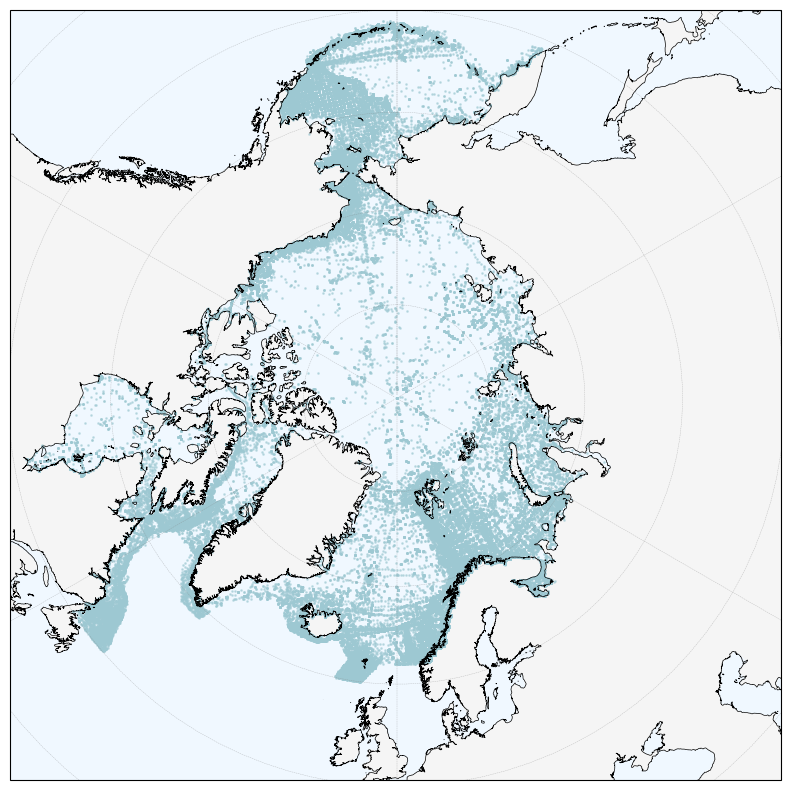

Plotted 242411 stations


In [48]:
# Load the dataset
file_path = "unique_stations_with_metadata.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

# Subset at station level

In [49]:
# Load the CSV file
csv_file = "unique_stations_with_metadata.csv"
csv_data = pd.read_csv(csv_file)
# Load the CSV file
excel_file = "merged_dataset_with_keep_column.csv"
excel_data = pd.read_csv(excel_file)
# Merge the dataframes on the 'datasetKey' column
merged_data = pd.merge(csv_data, excel_data[['datasetKey', 'Keep']], on='datasetKey', how='left')
# Save the updated CSV
output_file = "unique_stations_with_status.csv"
merged_data.to_csv(output_file, index=False)
print(f"Updated CSV saved as {output_file}")

Updated CSV saved as unique_stations_with_status.csv


Check if any stations lack entries in the Keep column

In [50]:
# Load the dataset
file_path = "unique_stations_with_status.csv"
df = pd.read_csv(file_path)
# Filter rows where the 'Keep' column is empty or null
missing_keep = df[df['Keep'].isna() | (df['Keep'] == '')]
# Drop duplicates based on the 'datasetKey' column
unique_missing_keep = missing_keep.drop_duplicates(subset='datasetKey')

In [51]:
# Count the number of rows with missing 'Keep' values
missing_count = len(unique_missing_keep)

# Check if there are any missing values
if missing_count > 0:
    print(f"⚠️ WARNING: {missing_count} stations have missing 'Keep' values!")
    print("\nDatasets with missing 'Keep' values:")
    print(unique_missing_keep[['datasetKey', 'title']].to_string(index=False))
    raise ValueError(f"Execution stopped: {missing_count} stations are missing 'Keep' values. Please review and update the data before continuing.")
else:
    print(f"✓ All stations have 'Keep' values assigned. Total stations checked: {len(df)}")

✓ All stations have 'Keep' values assigned. Total stations checked: 242411


In [52]:
# Load the updated CSV file
input_file = "unique_stations_with_status.csv"
data = pd.read_csv(input_file)
# Define the unique classes in the 'Keep' column
classes = ['F', 'P', 'U', 'R']
# Loop through each class and create a subset
for cls in classes:
    subset = data[data['Keep'] == cls]  # Filter rows where 'Keep' equals the class
    output_file = f"unique_stations_with_status_{cls}.csv"  # Create a filename for the subset
    subset.to_csv(output_file, index=False)  # Save the subset to a new CSV file
    print(f"Saved subset for class '{cls}' as {output_file} with {len(subset)} stations.")
# Print the total count for each class
print("\nRecord counts per class:")
for cls in classes:
    count = len(data[data['Keep'] == cls])
    print(f"Class '{cls}': {count} stations")

Saved subset for class 'F' as unique_stations_with_status_F.csv with 72779 stations.
Saved subset for class 'P' as unique_stations_with_status_P.csv with 107995 stations.
Saved subset for class 'U' as unique_stations_with_status_U.csv with 36666 stations.
Saved subset for class 'R' as unique_stations_with_status_R.csv with 24971 stations.

Record counts per class:
Class 'F': 72779 stations
Class 'P': 107995 stations
Class 'U': 36666 stations
Class 'R': 24971 stations


## Check samplingProtocol in P subset

In [53]:
# Load the CSV file
input_file = "unique_stations_with_status_P.csv"
output_file = "P_gear.csv"

# Read the CSV into a DataFrame
df = pd.read_csv(input_file)

# Filter out rows where samplingProtocol is null or empty
df = df[df['samplingProtocol'].notna() & (df['samplingProtocol'] != '')]

# Select the relevant columns
columns_to_keep = ['samplingProtocol', 'datasetKey', 'title', 'creator', 'abstract', 'citation']

# Drop duplicates based on the combination of datasetKey and samplingProtocol
unique_df = df[columns_to_keep].drop_duplicates(subset=['datasetKey', 'samplingProtocol'])

# Save the result to a new CSV file
unique_df.to_csv(output_file, index=False)

print(f"File with unique datasetKey-samplingProtocol combinations saved as {output_file}")
print(f"Total records with non-empty samplingProtocol: {len(unique_df)}")

File with unique datasetKey-samplingProtocol combinations saved as P_gear.csv
Total records with non-empty samplingProtocol: 678


## Key in gear classification in new file

In [56]:
# Load the CSV and Excel files
p_gear = pd.read_csv("P_gear.csv")
# Remove rows where samplingProtocol is NaN
p_gear = p_gear.dropna(subset=['samplingProtocol'])
print(f"After removing NaN samplingProtocol: {len(p_gear)} rows")

p_gear_edited = pd.read_csv("P_gear_edited.csv")
# Merge the 'Filter' column from P_gear_edited into P_gear using samplingProtocol and DatasetKey as keys
merged = pd.merge(
    p_gear,
    p_gear_edited[['samplingProtocol', 'datasetKey', 'Filter']],  # Select only the relevant columns
    on=['samplingProtocol', 'datasetKey'],  # Use these columns as keys
    how='left'  # Perform a left join to keep all rows from P_gear
)
# Save the updated dataset to a new file
merged.to_csv("P_gear_main.csv", index=False)
# Print a message
print("Merged dataset saved as 'P_gear_main.csv'")

After removing NaN samplingProtocol: 678 rows
Merged dataset saved as 'P_gear_main.csv'


Manually label gear types in P_gear_main.csv according to P, U, F or R. Save as P_gear_edited.csv. 

In [57]:
# Load the P_gear_main.csv file
p_gear_main_file = "P_gear_main.csv"
p_gear_main_df = pd.read_csv(p_gear_main_file)

# Count the number of records with missing 'Filter' values
missing_filter_count = p_gear_main_df['Filter'].isna().sum() + (p_gear_main_df['Filter'] == '').sum()
# Check if there are any missing values
if missing_filter_count > 0:
    print(f"⚠️ WARNING: {missing_filter_count} stations have missing 'Filter' values in P_gear_main.csv!")
    print("\nStations with missing 'Filter' values:")
    missing_filter_records = p_gear_main_df[p_gear_main_df['Filter'].isna() | (p_gear_main_df['Filter'] == '')]
    print(missing_filter_records[['samplingProtocol', 'datasetKey', 'title']].to_string(index=False))
    print("\nPlease review and update the 'Filter' column before continuing.")
    raise ValueError(f"Execution stopped: {missing_filter_count} stations are missing 'Filter' values.")
else:
    print(f"✓ All stations have 'Filter' values assigned. Total stations checked: {len(p_gear_main_df)}")

✓ All stations have 'Filter' values assigned. Total stations checked: 678


Go through and check if need for update. Save updated file as P_gear_edited.csv. 


## Distribute P subset over the other subsets, depending on gear type

In [58]:
# Original source files
file_p = "unique_stations_with_status_P.csv"
file_f = "unique_stations_with_status_F.csv"
file_u = "unique_stations_with_status_U.csv"
file_r = "unique_stations_with_status_R.csv"

# Output file paths
p_post_gear = "P_post_gear.csv"
f_post_gear = "F_post_gear.csv"
u_post_gear = "U_post_gear.csv"
r_post_gear = "R_post_gear.csv"

# Read the gear classification data
file_p_gear = "P_gear_edited.csv"
gear_data = pd.read_csv(file_p_gear)

# Ensure the relevant columns exist
if 'samplingProtocol' not in gear_data.columns or 'datasetKey' not in gear_data.columns or 'Filter' not in gear_data.columns:
    raise ValueError("The P_gear_edited.csv file must contain 'samplingProtocol', 'datasetKey', and 'Filter' columns.")

print("Step 1: Processing P file and adding Filter column")
print("="*50)
# Load the P source file
p_data = pd.read_csv(file_p)

# Merge with the gear data to add Filter column
if 'samplingProtocol' not in p_data.columns or 'datasetKey' not in p_data.columns:
    raise ValueError(f"The file {file_p} must contain 'samplingProtocol' and 'datasetKey' columns.")

p_merged = p_data.merge(
    gear_data[['samplingProtocol', 'datasetKey', 'Filter']], 
    on=['samplingProtocol', 'datasetKey'], 
    how='left'
)

print(f"P file rows: {len(p_merged)}")

# Separate rows from P based on the Filter column
f_rows_from_p = p_merged[p_merged['Filter'] == 'F']
r_rows_from_p = p_merged[p_merged['Filter'] == 'R']
u_rows_from_p = p_merged[p_merged['Filter'] == 'U']

# Remaining rows in P (Filter not F, R, or U)
p_data_remaining = p_merged[~p_merged['Filter'].isin(['F', 'R', 'U'])]

print(f"  Records classified as F: {len(f_rows_from_p)}")
print(f"  Records classified as R: {len(r_rows_from_p)}")
print(f"  Records classified as U: {len(u_rows_from_p)}")
print(f"  Records remaining in P: {len(p_data_remaining)}")

# Save the updated P_post_gear file
p_data_remaining.to_csv(p_post_gear, index=False)
print(f"\nSaved {p_post_gear} with {len(p_data_remaining)} rows")

# Function to recreate file from original source + redistributed records
def recreate_file(original_source_file, output_file, redistributed_rows, gear_data):
    # Load the original source file
    original_data = pd.read_csv(original_source_file)
    
    # Add Filter column to original data
    merged_original = original_data.merge(
        gear_data[['samplingProtocol', 'datasetKey', 'Filter']], 
        on=['samplingProtocol', 'datasetKey'], 
        how='left'
    )
    
    # Combine with redistributed rows from P
    combined_data = pd.concat([merged_original, redistributed_rows], ignore_index=True)
    
    # Save the combined file
    combined_data.to_csv(output_file, index=False)
    
    print(f"  Original records from {original_source_file}: {len(merged_original)}")
    print(f"  Redistributed records from P: {len(redistributed_rows)}")
    print(f"  Total rows in {output_file}: {len(combined_data)}")

print("\n" + "="*50)
print("Step 2: Recreating F, R, U files with redistributed records")
print("="*50)

# Recreate each file from scratch (idempotent operation)
print(f"\nRecreating {f_post_gear}:")
recreate_file(file_f, f_post_gear, f_rows_from_p, gear_data)

print(f"\nRecreating {r_post_gear}:")
recreate_file(file_r, r_post_gear, r_rows_from_p, gear_data)

print(f"\nRecreating {u_post_gear}:")
recreate_file(file_u, u_post_gear, u_rows_from_p, gear_data)

# Print final summary
print(f"\n{'='*50}")
print("FINAL SUMMARY")
print(f"{'='*50}")
print(f"{p_post_gear}: {len(p_data_remaining)} rows")
print(f"{f_post_gear}: created (original F + {len(f_rows_from_p)} from P)")
print(f"{r_post_gear}: created (original R + {len(r_rows_from_p)} from P)")
print(f"{u_post_gear}: created (original U + {len(u_rows_from_p)} from P)")

Step 1: Processing P file and adding Filter column
P file rows: 107995
  Records classified as F: 19862
  Records classified as R: 206
  Records classified as U: 0
  Records remaining in P: 87927

Saved P_post_gear.csv with 87927 rows

Step 2: Recreating F, R, U files with redistributed records

Recreating F_post_gear.csv:
  Original records from unique_stations_with_status_F.csv: 72779
  Redistributed records from P: 19862
  Total rows in F_post_gear.csv: 92641

Recreating R_post_gear.csv:
  Original records from unique_stations_with_status_R.csv: 24971
  Redistributed records from P: 206
  Total rows in R_post_gear.csv: 25177

Recreating U_post_gear.csv:
  Original records from unique_stations_with_status_U.csv: 36666
  Redistributed records from P: 0
  Total rows in U_post_gear.csv: 36666

FINAL SUMMARY
P_post_gear.csv: 87927 rows
F_post_gear.csv: created (original F + 19862 from P)
R_post_gear.csv: created (original R + 206 from P)
U_post_gear.csv: created (original U + 0 from P)


## Visualize subset coverage

C:\Users\hamod4691\AppData\Local\Temp\ipykernel_18980\3161527762.py:3: DtypeWarning: Columns (0: Filter) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


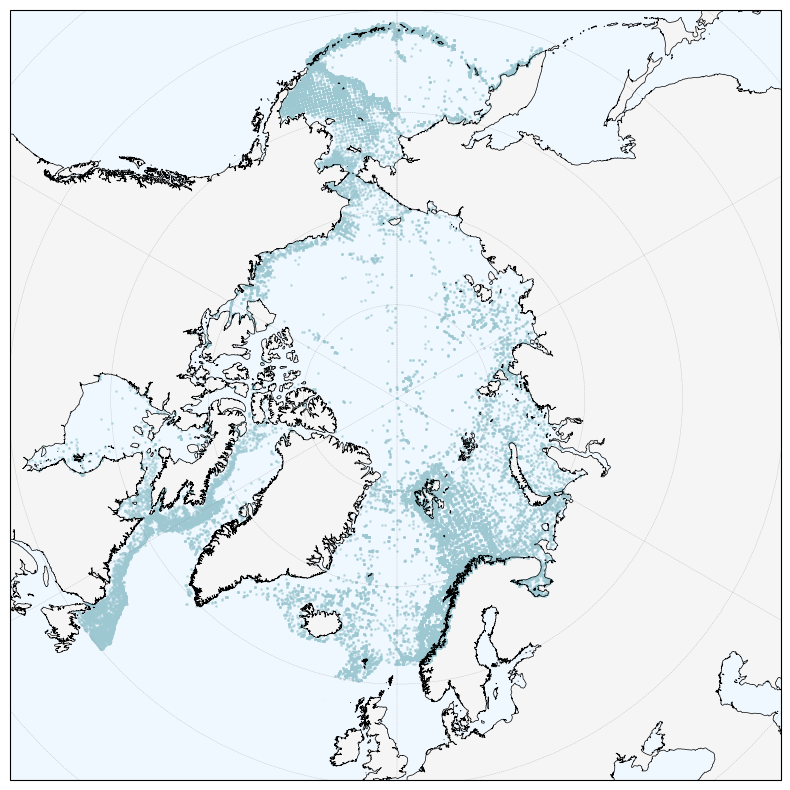

Plotted 92641 stations


In [59]:
# Load the dataset
file_path = "F_post_gear.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

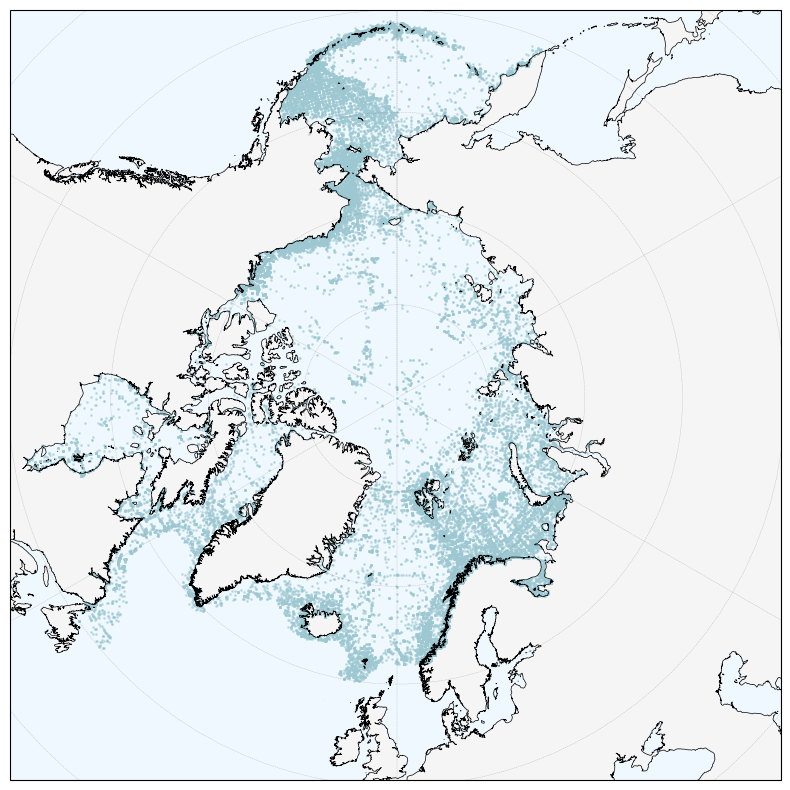

Plotted 87927 stations


In [60]:
# Load the dataset
file_path = "P_post_gear.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

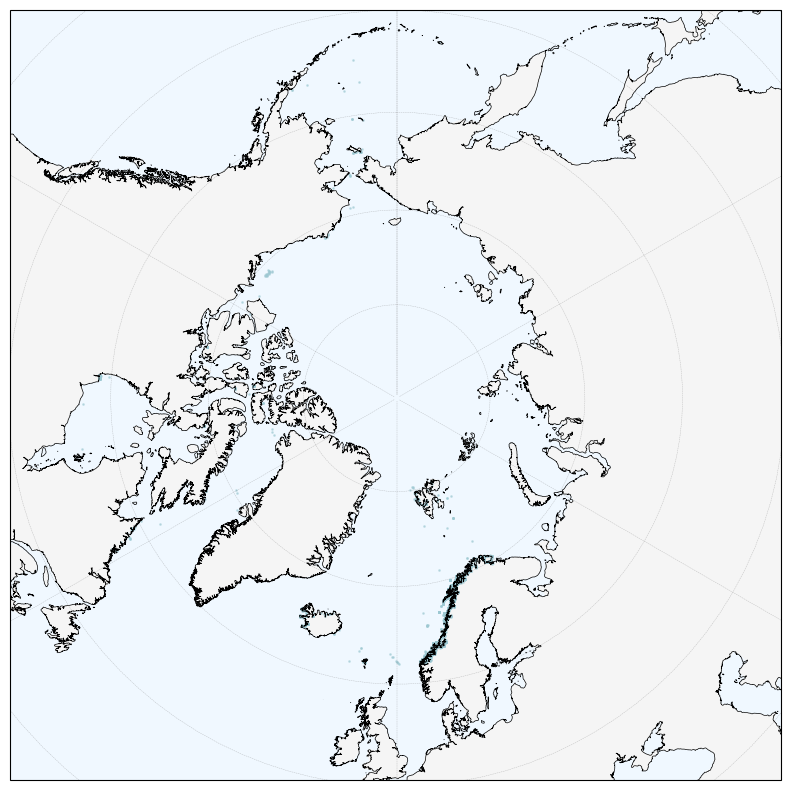

Plotted 36666 stations


In [61]:
# Load the dataset
file_path = "U_post_gear.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

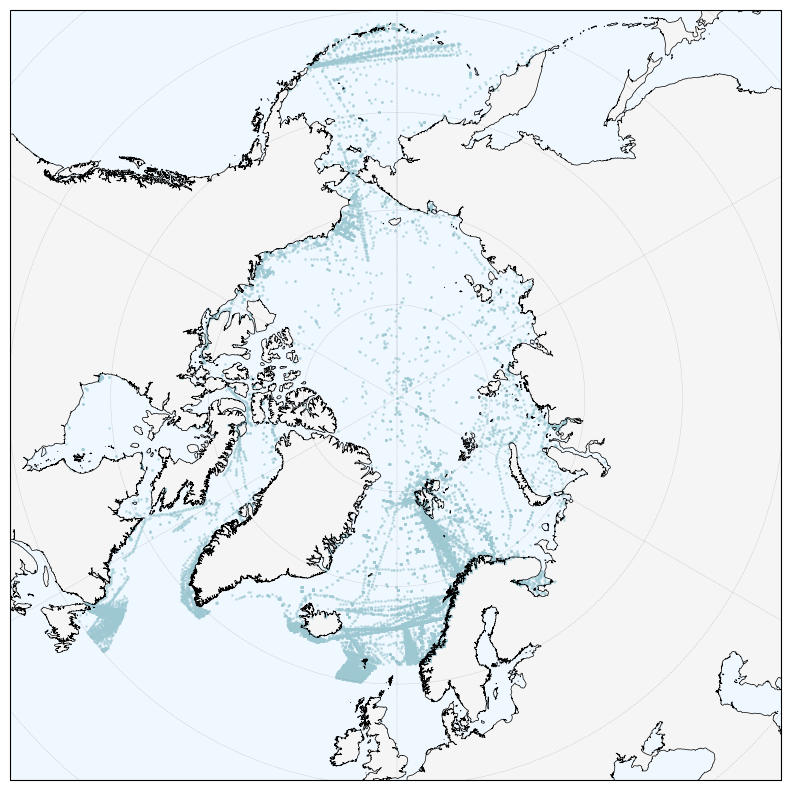

Plotted 25177 stations


In [62]:
# Load the dataset
file_path = "R_post_gear.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

# Subset at records level

In [63]:
# File paths
file_f = "F_post_gear.csv"
file_p = "P_post_gear.csv"
file_u = "U_post_gear.csv"
file_r = "R_post_gear.csv"
gbif_file = "gbif_filtered_dataset.parquet"
# Output files
output_f = "gbif_subset_F.parquet"
output_p = "gbif_subset_P.parquet"
output_u = "gbif_subset_U.parquet"
output_r = "gbif_subset_R.parquet"
output_unmatched = "unmatched.parquet"
# Step 1: Load the unique_stations_with_status files
print("Loading unique_stations_with_status files...")
status_f = pd.read_csv(file_f, usecols=["decimalLatitude", "decimalLongitude", "datasetKey"])
status_p = pd.read_csv(file_p, usecols=["decimalLatitude", "decimalLongitude", "datasetKey"])
status_u = pd.read_csv(file_u, usecols=["decimalLatitude", "decimalLongitude", "datasetKey"])
status_r = pd.read_csv(file_r, usecols=["decimalLatitude", "decimalLongitude", "datasetKey"])
# Debug: Check number of records
print("Number of records in F:", len(status_f))
print("Number of records in P:", len(status_p))
print("Number of records in U:", len(status_u))
print("Number of records in R:", len(status_r))
# Convert columns to consistent data types
status_f["decimalLatitude"] = status_f["decimalLatitude"].astype(float)
status_f["decimalLongitude"] = status_f["decimalLongitude"].astype(float)
status_f["datasetKey"] = status_f["datasetKey"].astype(str)
status_p["decimalLatitude"] = status_p["decimalLatitude"].astype(float)
status_p["decimalLongitude"] = status_p["decimalLongitude"].astype(float)
status_p["datasetKey"] = status_p["datasetKey"].astype(str)
status_u["decimalLatitude"] = status_u["decimalLatitude"].astype(float)
status_u["decimalLongitude"] = status_u["decimalLongitude"].astype(float)
status_u["datasetKey"] = status_u["datasetKey"].astype(str)
status_r["decimalLatitude"] = status_r["decimalLatitude"].astype(float)
status_r["decimalLongitude"] = status_r["decimalLongitude"].astype(float)
status_r["datasetKey"] = status_r["datasetKey"].astype(str)
# Convert to sets of tuples for fast lookup
set_f = set(status_f.itertuples(index=False, name=None))
set_p = set(status_p.itertuples(index=False, name=None))
set_u = set(status_u.itertuples(index=False, name=None))
set_r = set(status_r.itertuples(index=False, name=None))
print("Loaded unique_stations_with_status files.")
# Step 2: Load the gbif_combined_dataset.parquet file
print("Loading gbif_filtered_dataset.parquet...")
gbif_data = pd.read_parquet(gbif_file)
# Convert columns to consistent data types
gbif_data["decimalLatitude"] = gbif_data["decimalLatitude"].astype(float)
gbif_data["decimalLongitude"] = gbif_data["decimalLongitude"].astype(float)
gbif_data["datasetKey"] = gbif_data["datasetKey"].astype(str)
# Debug: Check number of records in GBIF dataset
print("Number of records in GBIF dataset:", len(gbif_data))
# Step 3: Split the dataset into subsets
print("Splitting dataset into subsets...")
# Create masks for each subset
tqdm.pandas()  # Enable tqdm for pandas
mask_f = gbif_data.progress_apply(
    lambda row: (row["decimalLatitude"], row["decimalLongitude"], row["datasetKey"]) in set_f, axis=1
)
mask_p = gbif_data.progress_apply(
    lambda row: (row["decimalLatitude"], row["decimalLongitude"], row["datasetKey"]) in set_p, axis=1
)
mask_u = gbif_data.progress_apply(
    lambda row: (row["decimalLatitude"], row["decimalLongitude"], row["datasetKey"]) in set_u, axis=1
)
mask_r = gbif_data.progress_apply(
    lambda row: (row["decimalLatitude"], row["decimalLongitude"], row["datasetKey"]) in set_r, axis=1
)
# Debug: Check number of matches for each subset
print("Number of matches in F:", mask_f.sum())
print("Number of matches in P:", mask_p.sum())
print("Number of matches in U:", mask_u.sum())
print("Number of matches in R:", mask_r.sum())
# Subset the data
subset_f = gbif_data[mask_f]
subset_p = gbif_data[mask_p]
subset_u = gbif_data[mask_u]
subset_r = gbif_data[mask_r]
# Find unmatched records
matched = mask_f | mask_p | mask_u | mask_r
subset_unmatched = gbif_data[~matched]
# Debug: Check number of unmatched records
print("Number of unmatched records:", len(subset_unmatched))
# Troubleshooting unmatched records
if len(subset_unmatched) > 0:
    print("Troubleshooting unmatched records...")
    # Save unmatched records to a CSV for inspection
    subset_unmatched.to_csv("unmatched_records.csv", index=False)
    print("Unmatched records saved to unmatched_records.csv")
    # Check for missing values in the unmatched records
    print("Checking for missing values in unmatched records...")
    print(subset_unmatched.isna().sum())
    # Check for unique datasetKeys in unmatched records
    print("Unique datasetKeys in unmatched records:")
    print(subset_unmatched["datasetKey"].unique())
    # Check for unique lat/lon combinations in unmatched records
    print("Unique lat/lon combinations in unmatched records:")
    print(subset_unmatched[["decimalLatitude", "decimalLongitude"]].drop_duplicates())
# Step 4: Save the subsets
print("Saving subsets...")
subset_f.to_parquet(output_f)
subset_p.to_parquet(output_p)
subset_u.to_parquet(output_u)
subset_r.to_parquet(output_r)
subset_unmatched.to_parquet(output_unmatched)
print("Subsets saved:")
print(f"F subset: {output_f}")
print(f"P subset: {output_p}")
print(f"U subset: {output_u}")
print(f"R subset: {output_r}")
print(f"Unmatched records: {output_unmatched}")

Loading unique_stations_with_status files...
Number of records in F: 92641
Number of records in P: 87927
Number of records in U: 36666
Number of records in R: 25177
Loaded unique_stations_with_status files.
Loading gbif_filtered_dataset.parquet...
Number of records in GBIF dataset: 3234211
Splitting dataset into subsets...


100%|██████████| 3234211/3234211 [00:24<00:00, 131008.96it/s]


Number of matches in F: 1183035
Number of matches in P: 1913864
Number of matches in U: 60683
Number of matches in R: 146978
Number of unmatched records: 0
Saving subsets...
Subsets saved:
F subset: gbif_subset_F.parquet
P subset: gbif_subset_P.parquet
U subset: gbif_subset_U.parquet
R subset: gbif_subset_R.parquet
Unmatched records: unmatched.parquet


## Redistribute records based on taxa

See the taxa that were selected in usageKeys.R

### Obligate benthos

In [64]:
# Load the subsets
subset_F = pd.read_parquet("gbif_subset_F.parquet")
subset_P = pd.read_parquet("gbif_subset_P.parquet")
# Define the conditions (keys are integers)
phylum_keys = [53, 105, 50, 75, 5967457, 74, 5963150, 63, 110, 5959089, 14]
class_keys = [137, 276, 346, 356, 256, 8365233, 354, 8066236, 309, 206]
order_keys = [705, 1415, 12204028, 1426, 1242, 1500, 1078, 5958700]
family_keys = [7325, 6960, 4531, 6191, 5379, 8691, 8146, 3363, 9676, 4529, 8888, 8895, 9272]
genus_keys = [8309288, 2268054, 2228475, 2268684, 2207284, 4283770, 2265855, 2202982]
# Function to clean and convert columns to Int64
def clean_and_convert_to_int64(column):
    # Replace invalid values (non-numeric or NaN) with pd.NA
    column = pd.to_numeric(column, errors='coerce')
    # Convert to nullable integer type (Int64)
    return column.astype('Int64')
# Clean and convert the key columns in subset_P
subset_P['phylumKey'] = clean_and_convert_to_int64(subset_P['phylumKey'])
subset_P['classKey'] = clean_and_convert_to_int64(subset_P['classKey'])
subset_P['orderKey'] = clean_and_convert_to_int64(subset_P['orderKey'])
subset_P['familyKey'] = clean_and_convert_to_int64(subset_P['familyKey'])
subset_P['genusKey'] = clean_and_convert_to_int64(subset_P['genusKey'])
# Filter records from subset_P that match the conditions, handling missing values with .notna()
records_to_move = subset_P[
    (subset_P['phylumKey'].notna() & subset_P['phylumKey'].isin(phylum_keys)) |
    (subset_P['classKey'].notna() & subset_P['classKey'].isin(class_keys)) |
    (subset_P['orderKey'].notna() & subset_P['orderKey'].isin(order_keys)) |
    (subset_P['familyKey'].notna() & subset_P['familyKey'].isin(family_keys)) |
    (subset_P['genusKey'].notna() & subset_P['genusKey'].isin(genus_keys))
]
# Count the number of records to move
num_records_moved = records_to_move.shape[0]
# Remove the filtered records from subset_P
subset_P = subset_P[~(
    (subset_P['phylumKey'].notna() & subset_P['phylumKey'].isin(phylum_keys)) |
    (subset_P['classKey'].notna() & subset_P['classKey'].isin(class_keys)) |
    (subset_P['orderKey'].notna() & subset_P['orderKey'].isin(order_keys)) |
    (subset_P['familyKey'].notna() & subset_P['familyKey'].isin(family_keys)) |
    (subset_P['genusKey'].notna() & subset_P['genusKey'].isin(genus_keys))
)]
# Add the filtered records to subset_F
subset_F = pd.concat([subset_F, records_to_move])
# Save the updated subsets back to Parquet files
subset_F.to_parquet("gbif_subset_F.parquet", index=False)
subset_P.to_parquet("gbif_subset_P.parquet", index=False)
# Print the number of records moved
print(f"Records moved successfully! Number of records moved: {num_records_moved}")

Records moved successfully! Number of records moved: 1603543


## Unique taxa lists with taxonKey

In [65]:
# Load the Parquet file
file_path = 'gbif_subset_F.parquet'  
# Read the Parquet file
data = pd.read_parquet(file_path)
# Select the relevant columns
columns_to_extract = ['acceptedScientificName', 'phylum', 'class', 'order', 'family', 'genus', 'taxonKey']
data_subset = data[columns_to_extract]
# Drop duplicates based on 'taxonKey' and remove rows with missing 'taxonKey'
unique_data = data_subset.drop_duplicates(subset='taxonKey').dropna(subset=['taxonKey'])
# Count the number of unique records based on 'taxonKey'
unique_count = unique_data['taxonKey'].nunique()
# Save the unique entries to a CSV file
output_file = 'unique_taxa_F.csv'  # Specify the output file name
unique_data.to_csv(output_file, index=False)
# Print the count and confirmation message
print(f"Number of unique taxonKeys: {unique_count}")
print(f"Unique records with taxonomy saved to {output_file}")

Number of unique taxonKeys: 10943
Unique records with taxonomy saved to unique_taxa_F.csv


In [66]:
# Load the Parquet file
file_path = 'gbif_subset_P.parquet'  
# Read the Parquet file
data = pd.read_parquet(file_path)
# Select the relevant columns
columns_to_extract = ['acceptedScientificName', 'phylum', 'class', 'order', 'family', 'genus', 'taxonKey']
data_subset = data[columns_to_extract]
# Drop duplicates based on 'taxonKey' and remove rows with missing 'taxonKey'
unique_data = data_subset.drop_duplicates(subset='taxonKey').dropna(subset=['taxonKey'])
# Count the number of unique records based on 'taxonKey'
unique_count = unique_data['taxonKey'].nunique()
# Save the unique entries to a CSV file
output_file = 'unique_taxa_P.csv'  # Specify the output file name
unique_data.to_csv(output_file, index=False)
# Print the count and confirmation message
print(f"Number of unique taxonKeys: {unique_count}")
print(f"Unique records with taxonomy saved to {output_file}")

Number of unique taxonKeys: 4738
Unique records with taxonomy saved to unique_taxa_P.csv


## Check taxon overlap

In [67]:
# Load data
unique_taxa_F = pd.read_csv('unique_taxa_F.csv')
unique_taxa_P = pd.read_csv('unique_taxa_P.csv')
unique_taxa_orig = pd.read_csv('gbif_taxonkey_original.csv')

# F and P: use taxonKey
set_F = set(unique_taxa_F['taxonKey'].dropna().unique())
set_P = set(unique_taxa_P['taxonKey'].dropna().unique())
set_O = set(unique_taxa_orig['TaxonKey'].dropna().unique())

print(len(set_F))
print(len(set_P))
print(len(set_O))

10943
4738
4970


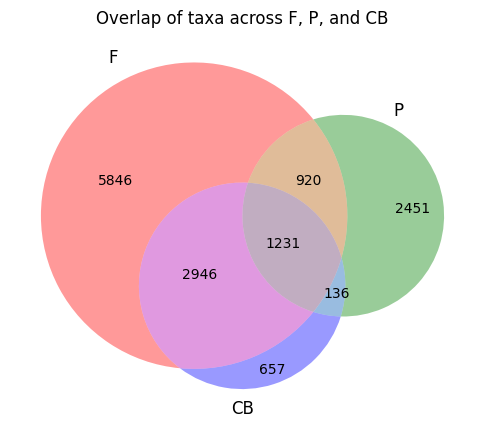

In [68]:
# This cell: create the 3-way Venn diagram for F, P, Original

plt.figure(figsize=(6, 6))
venn3([set_F, set_P, set_O], set_labels=('F', 'P', 'CB'))
plt.title('Overlap of taxa across F, P, and CB')
plt.show()

## Filter 'partial' using 'full' + 'original'

In [69]:
# Load the CSV files
unique_taxa_P = pd.read_csv("unique_taxa_P.csv")
unique_taxa_F = pd.read_csv("unique_taxa_F.csv")
gbif_taxonkey_original = pd.read_csv("gbif_taxonkey_original.csv")
# Create sets of taxonKeys from the other files
taxon_keys_F = set(unique_taxa_F['taxonKey'])
taxon_keys_gbif = set(gbif_taxonkey_original['TaxonKey'])
# Subset the records
P_benthic = unique_taxa_P[unique_taxa_P['taxonKey'].isin(taxon_keys_F | taxon_keys_gbif)]
P_non_benthic = unique_taxa_P[~unique_taxa_P['taxonKey'].isin(taxon_keys_F | taxon_keys_gbif)]
# Save the subsets to new CSV files
P_benthic.to_csv("P_benthic.csv", index=False)
P_non_benthic.to_csv("P_uncertain.csv", index=False)

print(len(P_benthic))
print(len(P_non_benthic))

2287
2451


In [70]:
# Load the CSV file
P_uncertain = pd.read_csv("P_uncertain.csv")
# Check the structure of the file to identify the relevant columns
print(P_uncertain.columns)
# Group by 'Phylum', 'Class', 'Order', 'Family', and 'Genus' and count the number of records
top_phyla = P_uncertain['phylum'].value_counts().head(10)
top_classes = P_uncertain['class'].value_counts().head(10)
top_orders = P_uncertain['order'].value_counts().head(10)
top_families = P_uncertain['family'].value_counts().head(10)
top_genera = P_uncertain['genus'].value_counts().head(10)
# Print the results
print("Top 10 Phyla:")
print(top_phyla)
print("\nTop 10 Classes:")
print(top_classes)
print("\nTop 10 Orders:")
print(top_orders)
print("\nTop 10 Families:")
print(top_families)
print("\nTop 10 Genera:")
print(top_genera)
# Save the results to CSV files if needed
top_phyla.to_csv("top_10_phyla.csv", header=["Count"])
top_classes.to_csv("top_10_classes.csv", header=["Count"])
top_orders.to_csv("top_10_orders.csv", header=["Count"])
top_families.to_csv("top_10_families.csv", header=["Count"])
top_genera.to_csv("top_10_genera.csv", header=["Count"])

Index(['acceptedScientificName', 'phylum', 'class', 'order', 'family', 'genus',
       'taxonKey'],
      dtype='str')
Top 10 Phyla:
phylum
Mollusca           985
Arthropoda         955
Cnidaria           242
Nematoda           223
Platyhelminthes     41
Chordata             4
Annelida             1
Name: count, dtype: int64

Top 10 Classes:
class
Gastropoda      952
Malacostraca    753
Hydrozoa        242
Ostracoda       171
Chromadorea     166
Cephalopoda      30
Maxillopoda      29
Turbellaria       5
Clitellata        1
Name: count, dtype: int64

Top 10 Orders:
order
Amphipoda          412
Neogastropoda      366
Littorinimorpha    178
Decapoda           146
Nudibranchia       128
Podocopida         122
Leptothecata       114
Isopoda            107
Anthoathecata      104
Rhabditida          74
Name: count, dtype: int64

Top 10 Families:
family
Buccinidae      180
Thoridae         48
Muricidae        44
Mangeliidae      42
Cytheruridae     34
Mysidae          30
Stenothoidae     30
V

In [71]:
# Load the CSV file
P_uncertain = pd.read_csv("P_benthic.csv")
# Check the structure of the file to identify the relevant columns
print(P_uncertain.columns)
# Group by 'Phylum', 'Class', 'Order', 'Family', and 'Genus' and count the number of records
top_phyla = P_uncertain['phylum'].value_counts().head(10)
top_classes = P_uncertain['class'].value_counts().head(10)
top_orders = P_uncertain['order'].value_counts().head(10)
top_families = P_uncertain['family'].value_counts().head(10)
top_genera = P_uncertain['genus'].value_counts().head(10)
# Print the results
print("Top 10 Phyla:")
print(top_phyla)
print("\nTop 10 Classes:")
print(top_classes)
print("\nTop 10 Orders:")
print(top_orders)
print("\nTop 10 Families:")
print(top_families)
print("\nTop 10 Genera:")
print(top_genera)
# Save the results to CSV files if needed
top_phyla.to_csv("top_10_phyla.csv", header=["Count"])
top_classes.to_csv("top_10_classes.csv", header=["Count"])
top_orders.to_csv("top_10_orders.csv", header=["Count"])
top_families.to_csv("top_10_families.csv", header=["Count"])
top_genera.to_csv("top_10_genera.csv", header=["Count"])

Index(['acceptedScientificName', 'phylum', 'class', 'order', 'family', 'genus',
       'taxonKey'],
      dtype='str')
Top 10 Phyla:
phylum
Arthropoda         1337
Mollusca            782
Cnidaria            138
Nematoda             18
Annelida              4
Phoronida             4
Platyhelminthes       3
Chordata              1
Name: count, dtype: int64

Top 10 Classes:
class
Malacostraca    1225
Gastropoda       761
Hydrozoa         136
Ostracoda         82
Maxillopoda       28
Cephalopoda       19
Chromadorea        8
Clitellata         3
Turbellaria        2
Copepoda           1
Name: count, dtype: int64

Top 10 Orders:
order
Amphipoda          818
Neogastropoda      239
Littorinimorpha    162
Isopoda            154
Decapoda           140
Nudibranchia       108
Leptothecata        80
Cephalaspidea       78
Podocopida          61
Mysida              55
Name: count, dtype: int64

Top 10 Families:
family
Oedicerotidae     83
Buccinidae        79
Mangeliidae       59
Uristidae        

## Merge unique taxa files for P benthic and F 

In [72]:
# Load the files
file1 = pd.read_csv('P_benthic.csv')
file2 = pd.read_csv('unique_taxa_F.csv')
# Get the column names
columns_file1 = set(file1.columns)
columns_file2 = set(file2.columns)
# Compare the columns
if columns_file1 == columns_file2:
    print("The files have the same columns.")
else:
    print("The files have different columns.")
    print("Columns in P_benthic.csv but not in unique_taxa_F.csv:", columns_file1 - columns_file2)
    print("Columns in unique_taxa_F.csv but not in P_benthic.csv:", columns_file2 - columns_file1)

The files have the same columns.


In [73]:
# Concatenate the files
merged_file = pd.concat([file1, file2])
# Save the merged file
merged_file.to_csv('unique_taxa_keep.csv', index=False)
print("Files have been merged and saved as 'unique_taxa_keep.csv'.")

Files have been merged and saved as 'unique_taxa_keep.csv'.


## Filter records in gbif_subset_P.parquet based on taxonKey in unique_taxa_keep

In [74]:
# Load the datasets
gbif_data = pd.read_parquet('gbif_subset_P.parquet')
unique_taxa = pd.read_csv('unique_taxa_keep.csv')
# Ensure taxonKey is the same data type in both datasets (integer)
gbif_data['taxonKey'] = gbif_data['taxonKey'].astype('Int64')  # Nullable integer type
unique_taxa['taxonKey'] = unique_taxa['taxonKey'].astype('Int64')  # Nullable integer type
# Filter records with matching taxonKey
records_keep = gbif_data[gbif_data['taxonKey'].isin(unique_taxa['taxonKey'])]
# Filter records without matching taxonKey
records_removed = gbif_data[~gbif_data['taxonKey'].isin(unique_taxa['taxonKey'])]
# Save the results as parquet files
records_keep.to_parquet('records_keep_P.parquet', index=False)
records_removed.to_parquet('records_removed_P.parquet', index=False)
print("Filtering complete. Files saved as 'records_keep_P.parquet' and 'records_removed_P.parquet'.")

Filtering complete. Files saved as 'records_keep_P.parquet' and 'records_removed_P.parquet'.


## Merge records for P benthic and F subsets

In [75]:
# Load the two Parquet files
file1 = "records_keep_P.parquet"
file2 = "gbif_subset_F.parquet"
df1 = pd.read_parquet(file1)
df2 = pd.read_parquet(file2)
# Check if the columns are the same
if list(df1.columns) == list(df2.columns):
    print("Columns match! Proceeding with the merge.")
else:
    print("Columns do not match! Here are the differences:")
    print("Columns in file1 but not in file2:", set(df1.columns) - set(df2.columns))
    print("Columns in file2 but not in file1:", set(df2.columns) - set(df1.columns))
# Merge the two DataFrames (row-wise)
merged_df = pd.concat([df1, df2], ignore_index=True)
# Save the merged DataFrame to a new Parquet file
merged_df.to_parquet("gbif_subset_merged_FP.parquet")
print("Files merged successfully and saved as 'gbif_subset_merged_FP.parquet'.")

Columns match! Proceeding with the merge.
Files merged successfully and saved as 'gbif_subset_merged_FP.parquet'.


## Filter out datasetKeys that are labelled as R or U

In [76]:
# Load the Parquet file
gbif_file = "gbif_subset_merged_FP.parquet"
gbif_df = pd.read_parquet(gbif_file)
# Load the Excel file
excel_file = "merged_dataset_with_keep_column.csv"
keep_df = pd.read_csv(excel_file)
# Merge the two DataFrames using 'datasetKey' as the key
# Assuming 'datasetKey' exists in both DataFrames
merged_df = gbif_df.merge(keep_df[['datasetKey', 'Keep']], on='datasetKey', how='left')
# Save the updated DataFrame to a new Parquet file
merged_df.to_parquet("gbif_subset_FP_status.parquet")
print("The updated file has been saved as 'gbif_subset_FP_status.parquet'.")

The updated file has been saved as 'gbif_subset_FP_status.parquet'.


In [77]:
# Load the Parquet file
file = "gbif_subset_FP_status.parquet"
df = pd.read_parquet(file)
# Count the number of records before filtering
initial_count = len(df)
print(f"Number of records before filtering: {initial_count}")
# Filter out records where the 'Keep' column has 'R' or 'U'
filtered_df = df[~df['Keep'].isin(['R', 'U'])]
# Count the number of records after filtering
filtered_count = len(filtered_df)
print(f"Number of records after filtering: {filtered_count}")
# Save the filtered DataFrame to a new Parquet file
filtered_df.to_parquet("filtered_keep_FP.parquet")
print("Filtered file has been saved as 'filtered_keep_FP.parquet'.")

Number of records before filtering: 3076601
Number of records after filtering: 3076601
Filtered file has been saved as 'filtered_keep_FP.parquet'.


# Stations in keep subset

In [78]:
# Load the records_keep.parquet file
records_keep = pd.read_parquet('filtered_keep_FP.parquet')
# Select the required columns
columns_to_keep = ['decimalLatitude', 'decimalLongitude', 'datasetKey', 'year', 'datasetName', 'depth']
filtered_data = records_keep[columns_to_keep]
# Drop duplicate rows based on decimalLatitude, decimalLongitude, and datasetKey
unique_combinations = filtered_data.drop_duplicates(subset=['decimalLatitude', 'decimalLongitude', 'datasetKey'])
# Save the result as a CSV file
unique_combinations.to_csv('stations_keep.csv', index=False)
print("File with unique combinations saved as 'stations_keep.csv'.")

File with unique combinations saved as 'stations_keep.csv'.


## Visualize

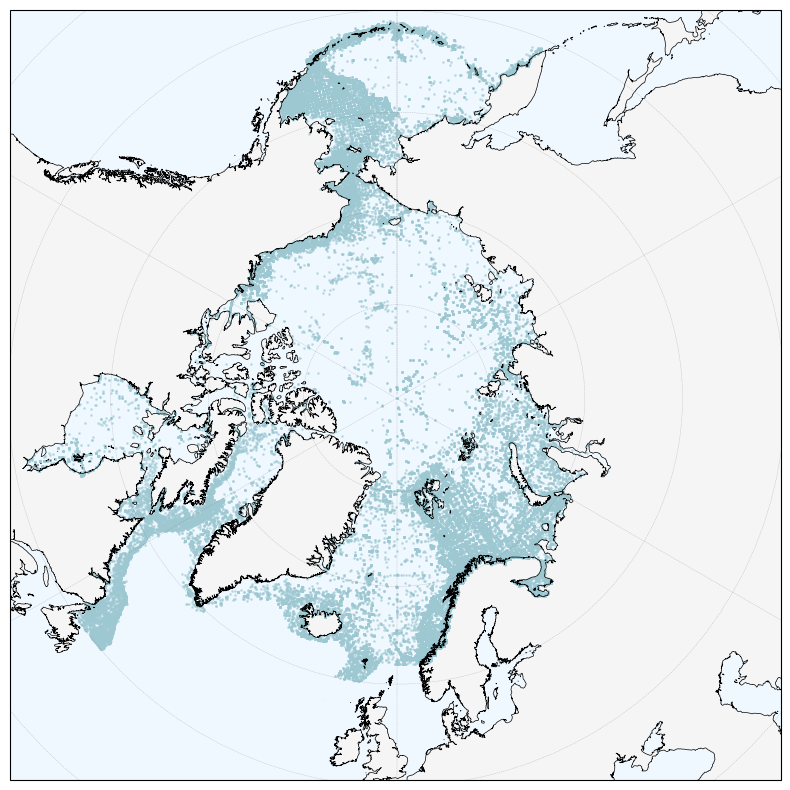

Plotted 150068 stations


In [79]:
# Load the dataset
file_path = "stations_keep.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

# Remove stations already in PANABIO

In [80]:
# Load the Biota sheet from the Excel file
biota_data = pd.read_excel('../CB/original.xlsx', sheet_name='Station')
# Select the required columns
columns_to_extract = ['StationID', 'DateStart', 'LatStart', 'LonStart']
cb_stations = biota_data[columns_to_extract].copy()  # Use .copy() to avoid the warning
# Create a new column 'Year' by extracting the year from the 'DateStart' column
cb_stations['Year'] = pd.to_datetime(cb_stations['DateStart']).dt.year
# Save the extracted data to a new Excel file
cb_stations.to_csv('CB_stations.csv', index=False)
print("Extracted data with 'Year' column saved as 'CB_stations.csv'.")

Extracted data with 'Year' column saved as 'CB_stations.csv'.


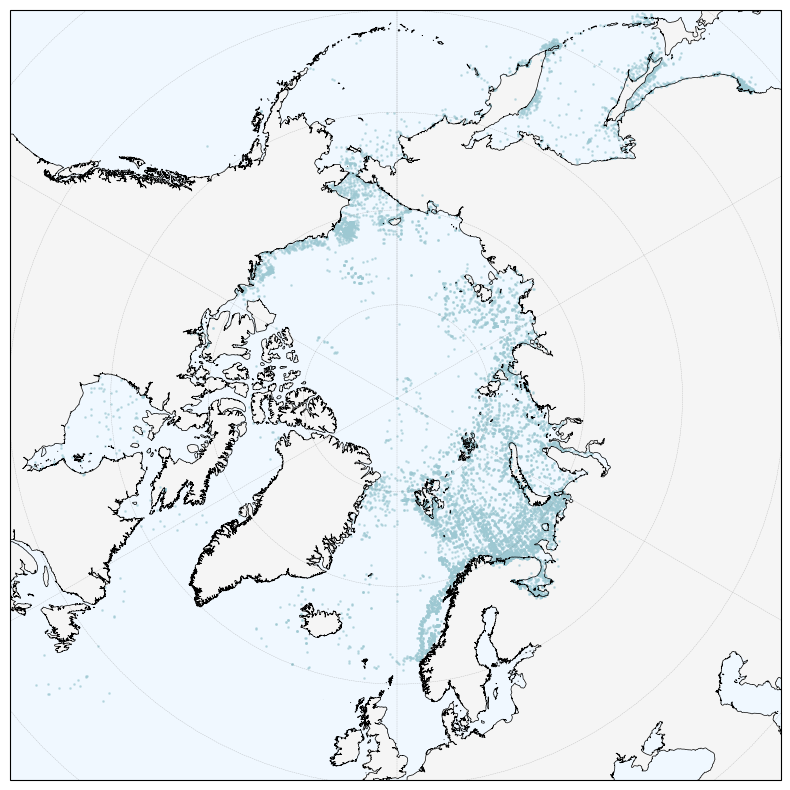

Plotted 12570 stations


In [81]:
# Load the dataset
file_path = "CB_stations.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['LonStart', 'LatStart']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['LonStart'].values, coords['LatStart'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

In [82]:
# Load the data from both files
cb_stations = pd.read_csv('CB_stations.csv')
stations_keep = pd.read_csv('stations_keep.csv')
# Normalize coordinates to 4 decimal places for consistency
cb_stations['LatStart'] = cb_stations['LatStart'].round(4)
cb_stations['LonStart'] = cb_stations['LonStart'].round(4)
stations_keep['decimalLatitude'] = stations_keep['decimalLatitude'].round(4)
stations_keep['decimalLongitude'] = stations_keep['decimalLongitude'].round(4)
# Count the number of stations before removing duplicates
stations_before = len(stations_keep)
# Standardize column names for comparison
cb_stations = cb_stations.rename(columns={'LatStart': 'decimalLatitude', 'LonStart': 'decimalLongitude', 'Year': 'year'})
# Perform a left merge to identify duplicates
merged = stations_keep.merge(
    cb_stations[['decimalLatitude', 'decimalLongitude', 'year']],
    on=['decimalLatitude', 'decimalLongitude', 'year'],
    how='left',
    indicator=True
)
# Filter out duplicates (stations that exist in CB_stations)
stations_keep_filtered = merged.query('_merge == "left_only"').drop(columns=['_merge'])
# Extract the filtered-out stations (duplicates)
filtered_out_stations = merged.query('_merge == "both"').drop(columns=['_merge'])
# Count the number of stations after removing duplicates
stations_after = len(stations_keep_filtered)
# Save the updated stations_keep file
stations_keep_filtered.to_csv('stations_keep_notCB.csv', index=False)
# Save the filtered-out stations to a separate file
filtered_out_stations.to_csv('stations_alreadyCB.csv', index=False)
# Print the results
print(f"Number of stations before removing duplicates: {stations_before}")
print(f"Number of stations after removing duplicates: {stations_after}")
print(f"Number of stations filtered out: {len(filtered_out_stations)}")

Number of stations before removing duplicates: 150068
Number of stations after removing duplicates: 147045
Number of stations filtered out: 4101


In [83]:
# Load the data from both files
metadata = pd.read_csv('merged_dataset_counts_with_metadata.csv')
stations_alreadyCB = pd.read_csv('stations_alreadyCB.csv')
# Select only the required columns from the metadata file
metadata_subset = metadata[['datasetKey', 'title', 'creator', 'dataset_doi', 'abstract']]
# Merge the metadata into stations_alreadyCB using datasetKey as the key
stations_with_metadata = stations_alreadyCB.merge(
    metadata_subset,
    on='datasetKey',
    how='left'  # Use left join to keep all rows from stations_alreadyCB
)
# Save the updated file
stations_with_metadata.to_csv('stations_alreadyCB.csv', index=False)
# Print a confirmation message
print("Columns 'title', 'creator', 'doi', and 'abstract' have been added to 'stations_alreadyCB.csv'.")
print("The updated file has been saved as 'stations_alreadyCB.csv'.")

Columns 'title', 'creator', 'doi', and 'abstract' have been added to 'stations_alreadyCB.csv'.
The updated file has been saved as 'stations_alreadyCB.csv'.


## Visualize removed stations

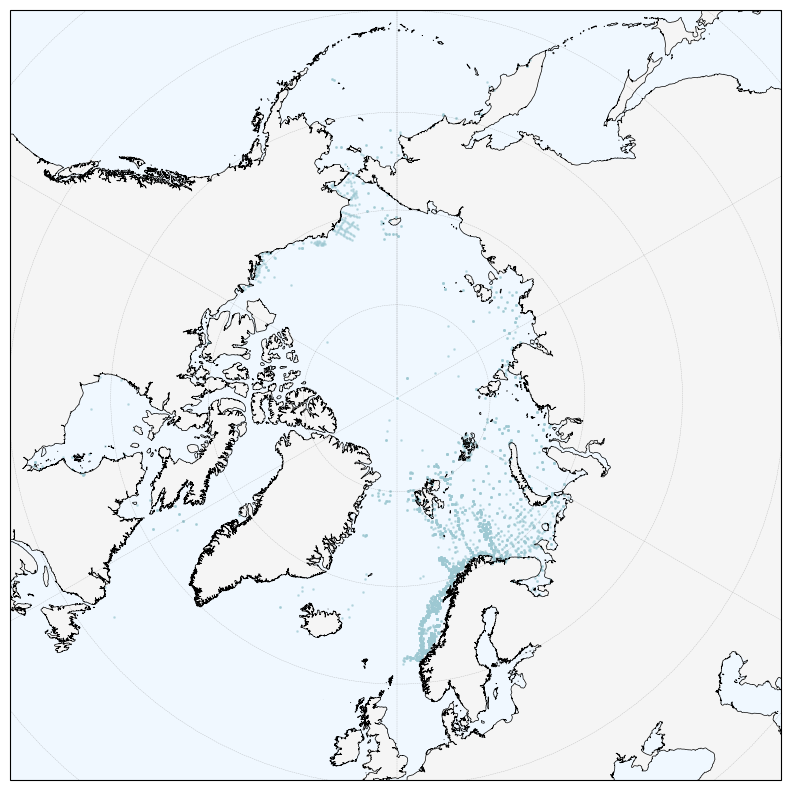

Plotted 4101 stations


In [84]:
# Load the dataset
file_path = "stations_alreadyCB.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

# Remove records belonging to PANABIO stations

In [85]:
# Load the data from both files
records_keep = pd.read_parquet('filtered_keep_FP.parquet')
stations_alreadyCB = pd.read_csv('stations_alreadyCB.csv')
# Convert coordinates to numeric (float) in both DataFrames
records_keep['decimalLatitude'] = pd.to_numeric(records_keep['decimalLatitude'], errors='coerce')
records_keep['decimalLongitude'] = pd.to_numeric(records_keep['decimalLongitude'], errors='coerce')
stations_alreadyCB['decimalLatitude'] = pd.to_numeric(stations_alreadyCB['decimalLatitude'], errors='coerce')
stations_alreadyCB['decimalLongitude'] = pd.to_numeric(stations_alreadyCB['decimalLongitude'], errors='coerce')
# Convert 'year' to integer in both DataFrames
records_keep['year'] = pd.to_numeric(records_keep['year'], errors='coerce').astype('Int64')
stations_alreadyCB['year'] = pd.to_numeric(stations_alreadyCB['year'], errors='coerce').astype('Int64')
# Normalize coordinates to 4 decimal places for consistency
records_keep['decimalLatitude'] = records_keep['decimalLatitude'].round(4)
records_keep['decimalLongitude'] = records_keep['decimalLongitude'].round(4)
stations_alreadyCB['decimalLatitude'] = stations_alreadyCB['decimalLatitude'].round(4)
stations_alreadyCB['decimalLongitude'] = stations_alreadyCB['decimalLongitude'].round(4)
# Select the relevant columns from stations_alreadyCB
stations_combinations = stations_alreadyCB[['decimalLatitude', 'decimalLongitude', 'year']].drop_duplicates()
# Perform an anti-join to remove matching rows
records_filtered = records_keep.merge(
    stations_combinations,
    on=['decimalLatitude', 'decimalLongitude', 'year'],
    how='left',
    indicator=True
).query('_merge == "left_only"').drop(columns=['_merge'])
# Save the filtered records to a new Parquet file
records_filtered.to_parquet('records_keep_notCB.parquet', index=False)
# Print the results
print(f"Number of records before filtering: {len(records_keep)}")
print(f"Number of records after filtering: {len(records_filtered)}")
print(f"Number of records removed: {len(records_keep) - len(records_filtered)}")

Number of records before filtering: 3076601
Number of records after filtering: 2983857
Number of records removed: 92744


In [86]:
# Load the Parquet file into a DataFrame
file_path = "records_keep_notCB.parquet"
df = pd.read_parquet(file_path)
# Check for duplicate rows
duplicates = df[df.duplicated()]
# Print the number of duplicate rows
print(f"Number of duplicate rows: {len(duplicates)}")
# If you want to drop duplicates and keep only unique rows:
df_unique = df.drop_duplicates()
# Save the unique rows back to a Parquet file (optional)
df_unique.to_parquet("records_keep_notCB.parquet", index=False)

Number of duplicate rows: 49064


# Datasets not in PANABIO

In [87]:
# Load the Parquet file
records_keep_notCB = pd.read_parquet('records_keep_notCB.parquet')
# Count the number of records per datasetKey
dataset_key_counts = records_keep_notCB['datasetKey'].value_counts().reset_index()
dataset_key_counts.columns = ['datasetKey', 'recordCount']
# Merge the counts back into the original DataFrame
records_keep_notCB = records_keep_notCB.merge(dataset_key_counts, on='datasetKey', how='left')
# Extract unique entries of 'datasetKey' along with their record counts
unique_dataset_keys = dataset_key_counts
# Save the unique dataset keys and their counts to a CSV file
unique_dataset_keys.to_csv('datasets_notCB.csv', index=False, header=True)
# Print confirmation
print(f"Extracted {len(unique_dataset_keys)} unique dataset keys and saved to 'datasets_notCB.csv'.")
print("Added a 'recordCount' column to the DataFrame.")

Extracted 544 unique dataset keys and saved to 'datasets_notCB.csv'.
Added a 'recordCount' column to the DataFrame.


In [88]:
# Load the data from both files
metadata = pd.read_csv('merged_dataset_counts_with_metadata.csv')
datasets_notCB = pd.read_csv('datasets_notCB.csv')
# Select only the required columns from the metadata file
metadata_subset = metadata[['datasetKey', 'title', 'creator', 'dataset_doi', 'abstract']]
# Merge the metadata into datasets_notCB using datasetKey as the key
datasets_with_metadata = datasets_notCB.merge(
    metadata_subset,
    on='datasetKey',
    how='left'  # Use left join to keep all rows from stations_alreadyCB
)
# Save the updated file
datasets_with_metadata.to_csv('datasets_notCB.csv', index=False)
# Print a confirmation message
print("Columns 'title', 'creator', 'doi', and 'abstract' have been added to 'datasets_notCB.csv'.")
print("The updated file has been saved as 'datasets_notCB.csv'.")

Columns 'title', 'creator', 'doi', and 'abstract' have been added to 'datasets_notCB.csv'.
The updated file has been saved as 'datasets_notCB.csv'.


In [89]:
# Load the Parquet file
records_keep_notCB = pd.read_parquet('records_keep_notCB.parquet')

# Get unique entries in organismQuantity and organismQuantityType columns
unique_organism_quantity = records_keep_notCB['organismQuantity'].unique()
unique_organism_quantity_type = records_keep_notCB['organismQuantityType'].unique()

# Print the unique entries
print("Unique entries in 'organismQuantity':")
print(unique_organism_quantity)
print(f"\nNumber of unique values: {len(unique_organism_quantity)}")

print("\n" + "="*50)
print("\nUnique entries in 'organismQuantityType':")
print(unique_organism_quantity_type)
print(f"\nNumber of unique values: {len(unique_organism_quantity_type)}")

Unique entries in 'organismQuantity':
<ArrowStringArray>
[   nan,    '3',    '2',    '6',    '5',    '1',   '36',    '4',   '13',   '12',
 ...
 '1552',  '236',  '611', '2304', '44.4', '62.5', '65.2', '42.9', '15.4',  '497']
Length: 2214, dtype: str

Number of unique values: 2214


Unique entries in 'organismQuantityType':
<ArrowStringArray>
[                                                         nan,                                                'individuals',           'Individantall makroalger (takson) per arealenhet',             'Relativ forekomst marin hardbunnsfauna (skala)',         'Individantall dyreplankton (takson) per arealenhet',                                           'Totalt tørrstoff',                      'Forekomst av arter/taksa dyreplankton',                               'Perfluortridekanoat (PFTrDS)',                                                'Fettinnhold', 'Individantall marin bløtbunnsfauna (takson) per arealenhet',
 ...
                               

# Key in aphiaID

In [94]:
# Load the parquet and Excel files
gbif_df = pd.read_parquet("records_keep_notCB.parquet")
aphia_df = pd.read_excel("unique_names_aphia_manual.xlsx")

# Prepare key columns
gbif_df['acceptedScientificName'] = gbif_df['acceptedScientificName'].astype(str).str.strip()
aphia_df['original_name'] = aphia_df['original_name'].astype(str).str.strip()

# Clean AphiaID to avoid ArrowInvalid conversion errors
aphia_df['AphiaID'] = (
    aphia_df['AphiaID']
    .astype(str)
    .str.replace('\u00a0', '', regex=False)
    .str.strip()
)
aphia_df['AphiaID'] = pd.to_numeric(aphia_df['AphiaID'], errors='coerce').astype('Int64')

# Merge AphiaID into the parquet data
merged_df = gbif_df.merge(
    aphia_df[['original_name', 'AphiaID']],
    left_on='acceptedScientificName',
    right_on='original_name',
    how='left'
).drop(columns=['original_name'])

# Save the result
merged_df.to_parquet("gbif_with_aphia.parquet", index=False)

print("Saved merged dataset with AphiaID as gbif_with_aphia.parquet")

Saved merged dataset with AphiaID as gbif_with_aphia.parquet


In [95]:
# Load the merged dataset with AphiaID
aphia_file = "gbif_with_aphia.parquet"
gbif_with_aphia = pd.read_parquet(aphia_file)

# Check for missing AphiaID values
missing_aphia = gbif_with_aphia['AphiaID'].isna().sum()

if missing_aphia > 0:
    print(f"⚠️ WARNING: {missing_aphia} records have missing AphiaID values.")
    raise ValueError("Execution stopped: Missing AphiaID values detected.")
else:
    print("✓ No missing AphiaID values found. Proceeding...")

✓ No missing AphiaID values found. Proceeding...


In [96]:
# Load merged dataset with AphiaID
gbif_with_aphia = pd.read_parquet("gbif_with_aphia.parquet")

# Filter records with missing AphiaID and extract unique acceptedScientificName
missing_aphia_names = (
    gbif_with_aphia[gbif_with_aphia["AphiaID"].isna()]
    [["acceptedScientificName"]]
    .dropna()
    .drop_duplicates()
)

# Save to file
output_file = "missing_aphia_unique_names.csv"
missing_aphia_names.to_csv(output_file, index=False)

print(f"Saved {len(missing_aphia_names)} unique names to {output_file}")

Saved 0 unique names to missing_aphia_unique_names.csv


# Key in measurementValue and measurementUnit 

from US_data

In [12]:
# Load GBIF parquet (already exists in earlier cells)
gbif_with_aphia = pd.read_parquet("gbif_with_aphia.parquet")

# Load verbatim measurement file (tab-delimited)
input_file = r"US_data\verbatim\dwc_measurementorfact.txt"
df_meas = pd.read_csv(input_file, sep="\t", low_memory=False)

# Filter by matching gbifID (normalize types to avoid mismatches)
meas_ids = df_meas["gbifid"].astype(str).str.strip()
gbif_ids = set(gbif_with_aphia["gbifID"].astype(str).str.strip())
filtered = df_meas[meas_ids.isin(gbif_ids)]

# Save filtered CSV in the same folder
output_file = r"US_data\verbatim\dwc_measurementorfact_filtered.csv"
filtered.to_csv(output_file, index=False)

print(f"Saved filtered file: {output_file} with {len(filtered)} rows")

Saved filtered file: US_data\verbatim\dwc_measurementorfact_filtered.csv with 29 rows


In [13]:
# Pivot measurementtype into columns for value and unit, keyed by gbifid
value_wide = filtered.pivot_table(
    index="gbifid",
    columns="measurementtype",
    values="measurementvalue",
    aggfunc="first"
)

unit_wide = filtered.pivot_table(
    index="gbifid",
    columns="measurementtype",
    values="measurementunit",
    aggfunc="first"
)

# Add suffixes to distinguish value vs unit
value_wide = value_wide.add_suffix("_value")
unit_wide = unit_wide.add_suffix("_unit")

# Combine into one wide table
meas_wide = value_wide.join(unit_wide).reset_index()

# Save filtered CSV in the same folder
output_file = r"US_data\verbatim\dwc_measurementorfact_filtered_wide.csv"
meas_wide.to_csv(output_file, index=False)

print(f"Saved filtered file: {output_file} with {len(meas_wide)} rows")

Saved filtered file: US_data\verbatim\dwc_measurementorfact_filtered_wide.csv with 29 rows


from eurasia_data

In [7]:
# Load GBIF parquet (already exists in earlier cells)
gbif_with_aphia = pd.read_parquet("gbif_with_aphia.parquet")

# Load verbatim measurement file (tab-delimited)
input_file = r"eurasia_data\verbatim\dwc_measurementorfact.txt"
df_meas = pd.read_csv(input_file, sep="\t", low_memory=False)

# Filter by matching gbifID (normalize types to avoid mismatches)
meas_ids = df_meas["gbifid"].astype(str).str.strip()
gbif_ids = set(gbif_with_aphia["gbifID"].astype(str).str.strip())
filtered = df_meas[meas_ids.isin(gbif_ids)]

# Save filtered CSV in the same folder
output_file = r"eurasia_data\verbatim\dwc_measurementorfact_filtered.csv"
filtered.to_csv(output_file, index=False)

print(f"Saved filtered file: {output_file} with {len(filtered)} rows")

Saved filtered file: eurasia_data\verbatim\dwc_measurementorfact_filtered.csv with 73623 rows


In [11]:
# Pivot measurementtype into columns for value and unit, keyed by gbifid
value_wide = filtered.pivot_table(
    index="gbifid",
    columns="measurementtype",
    values="measurementvalue",
    aggfunc="first"
)

unit_wide = filtered.pivot_table(
    index="gbifid",
    columns="measurementtype",
    values="measurementunit",
    aggfunc="first"
)

# Add suffixes to distinguish value vs unit
value_wide = value_wide.add_suffix("_value")
unit_wide = unit_wide.add_suffix("_unit")

# Combine into one wide table
meas_wide = value_wide.join(unit_wide).reset_index()

# Save filtered CSV in the same folder
output_file = r"eurasia_data\verbatim\dwc_measurementorfact_filtered_wide.csv"
meas_wide.to_csv(output_file, index=False)

print(f"Saved filtered file: {output_file} with {len(meas_wide)} rows")

Saved filtered file: eurasia_data\verbatim\dwc_measurementorfact_filtered_wide.csv with 37456 rows


Merge files

In [14]:
# Load both wide measurement files
us_file = r"US_data\verbatim\dwc_measurementorfact_filtered_wide.csv"
eurasia_file = r"eurasia_data\verbatim\dwc_measurementorfact_filtered_wide.csv"

us_wide = pd.read_csv(us_file)
eurasia_wide = pd.read_csv(eurasia_file)

# Concatenate and remove duplicates
merged = pd.concat([us_wide, eurasia_wide], ignore_index=True)
before = len(merged)
merged = merged.drop_duplicates()
after = len(merged)

print(f"Rows before deduplication: {before}")
print(f"Rows after deduplication: {after}")
print(f"Duplicates removed: {before - after}")

# Save to main GBIF folder
output_path = "mof_merged.csv"
merged.to_csv(output_path, index=False)
print(f"Saved merged file to {output_path}")

Rows before deduplication: 37485
Rows after deduplication: 37485
Duplicates removed: 0
Saved merged file to mof_merged.csv


Key in the mof information to the main records file

In [15]:
# Load merged MOF file
mof_df = pd.read_csv(output_path)

# Normalize key types
mof_df["gbifid"] = mof_df["gbifid"].astype(str).str.strip()
gbif_with_aphia["gbifID"] = gbif_with_aphia["gbifID"].astype(str).str.strip()

# Merge MOF columns into GBIF data
gbif_with_mof = gbif_with_aphia.merge(
    mof_df,
    left_on="gbifID",
    right_on="gbifid",
    how="left"
).drop(columns=["gbifid"])

# Save to parquet
gbif_with_mof.to_parquet("gbif_with_mof.parquet", index=False)

print(f"Saved merged dataset as gbif_with_mof.parquet with {len(gbif_with_mof)} rows.")

Saved merged dataset as gbif_with_mof.parquet with 2991470 rows.


Comparisons of mof columns

In [16]:
# Compare lifeStage vs Transformation stage_value overlap by gbifID
tmp = gbif_with_mof[["gbifID", "lifeStage", "Transformation stage_value"]].copy()

# Presence flags
tmp["lifeStage_present"] = tmp["lifeStage"].notna() & (tmp["lifeStage"].astype(str).str.strip() != "")
tmp["transformation_present"] = tmp["Transformation stage_value"].notna() & (
    tmp["Transformation stage_value"].astype(str).str.strip() != ""
)

# Summary counts
summary = {
    "total_rows": len(tmp),
    "lifeStage_present": int(tmp["lifeStage_present"].sum()),
    "transformation_present": int(tmp["transformation_present"].sum()),
    "both_present": int((tmp["lifeStage_present"] & tmp["transformation_present"]).sum()),
    "lifeStage_only": int((tmp["lifeStage_present"] & ~tmp["transformation_present"]).sum()),
    "transformation_only": int((~tmp["lifeStage_present"] & tmp["transformation_present"]).sum()),
    "neither_present": int((~tmp["lifeStage_present"] & ~tmp["transformation_present"]).sum()),
}
print(summary)

# Overlap by gbifID (unique IDs)
by_id = tmp.groupby("gbifID")[["lifeStage_present", "transformation_present"]].any()
id_summary = {
    "unique_gbifIDs": len(by_id),
    "ids_with_lifeStage": int(by_id["lifeStage_present"].sum()),
    "ids_with_transformation": int(by_id["transformation_present"].sum()),
    "ids_with_both": int((by_id["lifeStage_present"] & by_id["transformation_present"]).sum()),
    "ids_with_only_lifeStage": int((by_id["lifeStage_present"] & ~by_id["transformation_present"]).sum()),
    "ids_with_only_transformation": int((~by_id["lifeStage_present"] & by_id["transformation_present"]).sum()),
}
print(id_summary)

# Optional: show value agreement where both present
both = tmp[tmp["lifeStage_present"] & tmp["transformation_present"]]
if len(both) > 0:
    agreement = (both["lifeStage"].astype(str).str.strip().str.lower() ==
                 both["Transformation stage_value"].astype(str).str.strip().str.lower())
    print(f"Value agreement where both present: {agreement.mean():.2%} ({agreement.sum()}/{len(agreement)})")

{'total_rows': 2991470, 'lifeStage_present': 3812, 'transformation_present': 38, 'both_present': 38, 'lifeStage_only': 3774, 'transformation_only': 0, 'neither_present': 2987658}
{'unique_gbifIDs': 2934793, 'ids_with_lifeStage': 3721, 'ids_with_transformation': 38, 'ids_with_both': 38, 'ids_with_only_lifeStage': 3683, 'ids_with_only_transformation': 0}
Value agreement where both present: 100.00% (38/38)


= it is enough to include lifeStage

same but with count and abundance: 

In [17]:
# Compare lifeStage vs Transformation stage_value overlap by gbifID
tmp = gbif_with_mof[["gbifID", "individualCount", "count_value"]].copy()

# Presence flags
tmp["individualCount_present"] = tmp["individualCount"].notna() & (tmp["individualCount"].astype(str).str.strip() != "")
tmp["count_value_present"] = tmp["count_value"].notna() & (
    tmp["count_value"].astype(str).str.strip() != ""
)

# Summary counts
summary = {
    "total_rows": len(tmp),
    "individualCount_present": int(tmp["individualCount_present"].sum()),
    "count_value_present": int(tmp["count_value_present"].sum()),
    "both_present": int((tmp["individualCount_present"] & tmp["count_value_present"]).sum()),
    "individualCount_only": int((tmp["individualCount_present"] & ~tmp["count_value_present"]).sum()),
    "count_value_only": int((~tmp["individualCount_present"] & tmp["count_value_present"]).sum()),
    "neither_present": int((~tmp["individualCount_present"] & ~tmp["count_value_present"]).sum()),
}
print(summary)

# Overlap by gbifID (unique IDs)
by_id = tmp.groupby("gbifID")[["individualCount_present", "count_value_present"]].any()
id_summary = {
    "unique_gbifIDs": len(by_id),
    "ids_with_individualCount": int(by_id["individualCount_present"].sum()),
    "ids_with_count_value": int(by_id["count_value_present"].sum()),
    "ids_with_both": int((by_id["individualCount_present"] & by_id["count_value_present"]).sum()),
    "ids_with_only_individualCount": int((by_id["individualCount_present"] & ~by_id["count_value_present"]).sum()),
    "ids_with_only_count_value": int((~by_id["individualCount_present"] & by_id["count_value_present"]).sum()),
}
print(id_summary)

# Optional: show value agreement where both present
both = tmp[tmp["individualCount_present"] & tmp["count_value_present"]]
if len(both) > 0:
    agreement = (both["individualCount"].astype(str).str.strip().str.lower() ==
                 both["count_value"].astype(str).str.strip().str.lower())
    print(f"Value agreement where both present: {agreement.mean():.2%} ({agreement.sum()}/{len(agreement)})")

{'total_rows': 2991470, 'individualCount_present': 2613546, 'count_value_present': 36, 'both_present': 0, 'individualCount_only': 2613546, 'count_value_only': 36, 'neither_present': 377888}
{'unique_gbifIDs': 2934793, 'ids_with_individualCount': 2565477, 'ids_with_count_value': 33, 'ids_with_both': 0, 'ids_with_only_individualCount': 2565477, 'ids_with_only_count_value': 33}


= count_value should be added to individualCount

In [18]:
# Load the parquet file
gbif_with_mof = pd.read_parquet("gbif_with_mof.parquet")

# Move count_value to individualCount where individualCount is missing and count_value is present
mask = gbif_with_mof['individualCount'].isna() & gbif_with_mof['count_value'].notna()
gbif_with_mof.loc[mask, 'individualCount'] = gbif_with_mof.loc[mask, 'count_value']

# Drop the count_value column
gbif_with_mof = gbif_with_mof.drop(columns=['count_value'])

# Save back to parquet
gbif_with_mof.to_parquet("gbif_with_mof.parquet", index=False)

print(f"Moved {mask.sum()} values from count_value to individualCount")
print(f"Removed count_value column. New shape: {gbif_with_mof.shape}")

Moved 36 values from count_value to individualCount
Removed count_value column. New shape: (2991470, 74)


# Check content in organismQuantityType, dynamicProperties and samplingEffort

In [19]:
# Extract unique values and save to CSV
org_qty = (
    gbif_with_mof["organismQuantityType"]
    .dropna()
    .astype(str)
    .str.strip()
    .loc[lambda s: s != ""]
    .drop_duplicates()
    .sort_values()
)

dyn_props = (
    gbif_with_mof["dynamicProperties"]
    .dropna()
    .astype(str)
    .str.strip()
    .loc[lambda s: s != ""]
    .drop_duplicates()
    .sort_values()
)

org_qty.to_csv("organismQuantityType.csv", index=False, header=["organismQuantityType"])
dyn_props.to_csv("dynamicProperties.csv", index=False, header=["dynamicProperties"])

print(f"Saved organismQuantityType.csv with {len(org_qty)} unique values")
print(f"Saved dynamicProperties.csv with {len(dyn_props)} unique values")

Saved organismQuantityType.csv with 123 unique values
Saved dynamicProperties.csv with 19217 unique values


In [25]:
# Filter records with non-empty dynamicProperties, excluding dataSheetURL entries
dyn_props = gbif_with_mof["dynamicProperties"].astype(str).str.strip()
dynamic_props_mask = (
    gbif_with_mof["dynamicProperties"].notna() &
    (dyn_props != "") &
    ~dyn_props.str.startswith('"""{""dataSheetURL""') &
    ~dyn_props.str.contains("SampleSize=#;", regex=False) &
    ~dyn_props.str.contains("SampleSize=0.1 m²;", regex=False)
)

gbif_dynamic = gbif_with_mof[dynamic_props_mask].copy()

# Save filtered parquet
gbif_dynamic.to_parquet("gbif_dynamicProperties.parquet", index=False)

print(f"Saved gbif_dynamicProperties.parquet with {len(gbif_dynamic)} records.")

Saved gbif_dynamicProperties.parquet with 33770 records.


Checking samplingEffort

In [2]:
# Load the parquet file
gbif_with_mof = pd.read_parquet("gbif_with_mof.parquet")

# Extract unique non-empty samplingEffort values
sampling_effort_unique = (
    gbif_with_mof["samplingEffort"]
    .dropna()
    .astype(str)
    .str.strip()
    .loc[lambda s: s != ""]
    .drop_duplicates()
    .sort_values()
)

print(f"Unique samplingEffort values: {len(sampling_effort_unique)}")
print(sampling_effort_unique.to_string(index=False))

Unique samplingEffort values: 29
                                              #
                                            #/l
                                         #/m**2
                                         0.1 m²
                                         0.5 m²
                                           1 m²
1 shrimp bottom-trawl/standardized tow (15 min)
1 shrimp bottom-trawl/standardized tow (24 min)
                                          1 tow
                                         10 cm²
                            111 analyzed images
                           1131 analyzed images
                                         15 cm²
                                       15.9 cm²
                            226 analyzed images
                            233 analyzed images
                             24 analyzed images
                                         25 cm²
                            256 analyzed images
                            405 analyzed images
       

# Move entries from organismQuantity to individualCount

In [7]:
# Load the parquet file
gbif_with_mof = pd.read_parquet("gbif_with_mof.parquet")

# Normalize fields
qty_type = gbif_with_mof["organismQuantityType"].astype(str).str.strip().str.lower()
qty = gbif_with_mof["organismQuantity"].astype(str).str.strip()

# Masks
type_mask = qty_type.isin(["individuals", "individuals per area"])
indiv_empty = gbif_with_mof["individualCount"].isna() | (
    gbif_with_mof["individualCount"].astype(str).str.strip() == ""
 )
qty_present = gbif_with_mof["organismQuantity"].notna() & (qty != "")

# Copy values where applicable, omit decimals
qty_num = pd.to_numeric(qty, errors="coerce")
copy_mask = type_mask & indiv_empty & qty_present & qty_num.notna()
copy_mask = copy_mask & (qty_num % 1 == 0)
gbif_with_mof.loc[copy_mask, "individualCount"] = qty_num[copy_mask].astype("Int64")

# Count failures where quantity missing
missing_qty_mask = type_mask & indiv_empty & ~qty_present
num_copied = int(copy_mask.sum())
num_missing_qty = int(missing_qty_mask.sum())

# Save back to parquet
gbif_with_mof.to_parquet("gbif_with_mof.parquet", index=False)

print(f"Copied {num_copied} values to individualCount.")
if num_missing_qty > 0:
    print(f"⚠️ {num_missing_qty} records could not be copied due to missing organismQuantity.")
else:
    print("✓ All eligible records had organismQuantity values.")

Copied 11444 values to individualCount.
⚠️ 18 records could not be copied due to missing organismQuantity.


I decided to omit the individual counts from this dataset, as the decimal numbers make it unclear what kind of count values they are

In [9]:
# Include taxonomy columns for the same decimal-and-type filter
qty_raw = gbif_with_mof["organismQuantity"].astype(str).str.strip()
decimal_mask = qty_raw.str.match(r"^-?\d+\.\d+$", na=False)

decimals_in_individuals_tax = gbif_with_mof.loc[
    decimal_mask & type_mask,
    [
        "organismQuantityType",
        "organismQuantity",
        "individualCount",
        "phylum",
        "acceptedScientificName",
        "datasetKey",
    ],
]

print(f"Decimal values within individuals/individuals per area: {decimals_in_individuals_tax.shape[0]}")
decimals_in_individuals_tax.head(50)

Decimal values within individuals/individuals per area: 121


,organismQuantityType,organismQuantity,individualCount,phylum,acceptedScientificName,datasetKey
1262151,individuals per area,1.16,<NA>,Cnidaria,Anthozoa,a786ae17-dcd8-4302-abb3-72d1a528b413
1262154,individuals per area,1.1,<NA>,Cnidaria,Actiniaria,a786ae17-dcd8-4302-abb3-72d1a528b413
1262162,individuals per area,2.66,<NA>,Cnidaria,"Gersemia rubiformis (Ehrenberg, 1834)",a786ae17-dcd8-4302-abb3-72d1a528b413
1262167,individuals per area,0.62,<NA>,Echinodermata,Asteroidea,a786ae17-dcd8-4302-abb3-72d1a528b413
1262169,individuals per area,0.45,<NA>,Mollusca,Gastropoda,a786ae17-dcd8-4302-abb3-72d1a528b413
1262174,individuals per area,0.65,<NA>,Annelida,Serpulidae,a786ae17-dcd8-4302-abb3-72d1a528b413
1262181,individuals per area,0.4,<NA>,Cnidaria,Cnidaria,a786ae17-dcd8-4302-abb3-72d1a528b413
1262185,individuals per area,0.08,<NA>,Arthropoda,"Colossendeis proboscidea (Sabine, 1824)",a786ae17-dcd8-4302-abb3-72d1a528b413
1262191,individuals per area,10.7,<NA>,Arthropoda,Arthropoda,a786ae17-dcd8-4302-abb3-72d1a528b413
1262199,individuals per area,0.83,<NA>,Arthropoda,Arthropoda,a786ae17-dcd8-4302-abb3-72d1a528b413


# Move entries from organismQuantity to individualsPerArea

In [5]:
# Load the parquet file
gbif_with_mof = pd.read_parquet("gbif_with_mof.parquet")

# Check for clashes with existing data
individualCount_clash = gbif_with_mof["individualCount"].notna() & gbif_with_mof["Abundance_value"].notna()
samplingEffort_clash = gbif_with_mof["samplingEffort"].notna() & gbif_with_mof["Abundance_unit"].notna()

clash_count_ic = individualCount_clash.sum()
clash_count_se = samplingEffort_clash.sum()

print(f"Clashes with individualCount: {clash_count_ic}")
print(f"Clashes with samplingEffort: {clash_count_se}")

if clash_count_ic > 0:
    print(f"  Rows with both individualCount and Abundance_value: {clash_count_ic}")
if clash_count_se > 0:
    print(f"  Rows with both samplingEffort and Abundance_unit: {clash_count_se}")

# Fill missing values only (don't overwrite existing data)
mask_ic = gbif_with_mof["individualCount"].isna() & gbif_with_mof["Abundance_value"].notna()
mask_se = gbif_with_mof["samplingEffort"].isna() & gbif_with_mof["Abundance_unit"].notna()

# Convert individualCount to float to accommodate the values
if mask_ic.sum() > 0:
    gbif_with_mof["individualCount"] = gbif_with_mof["individualCount"].astype('Float64')
    gbif_with_mof.loc[mask_ic, "individualCount"] = gbif_with_mof.loc[mask_ic, "Abundance_value"]

gbif_with_mof.loc[mask_se, "samplingEffort"] = gbif_with_mof.loc[mask_se, "Abundance_unit"]

filled_ic = mask_ic.sum()
filled_se = mask_se.sum()

print(f"\nFilled {filled_ic} rows for individualCount from Abundance_value")
print(f"Filled {filled_se} rows for samplingEffort from Abundance_unit")

# Save updated dataset
gbif_with_mof.to_parquet("gbif_with_mof.parquet", index=False)
print("\nSaved updated file as gbif_with_mof.parquet.")

Clashes with individualCount: 0
Clashes with samplingEffort: 0

Filled 36962 rows for individualCount from Abundance_value
Filled 36962 rows for samplingEffort from Abundance_unit

Saved updated file as gbif_with_mof.parquet.


In [25]:
gbif_with_mof = pd.read_parquet("gbif_with_mof.parquet")

# Normalize organismQuantityType for matching
oq_type = gbif_with_mof["organismQuantityType"].astype(str).str.strip().str.lower()
oq_val = gbif_with_mof["organismQuantity"].astype(str).str.strip()

# Match target types
type_match = oq_type.isin(["individuals per square metre", "m2", "square metre"])

# Ensure quantity is present and convert to numeric
val_present = gbif_with_mof["organismQuantity"].notna() & (oq_val != "")
oq_num = pd.to_numeric(oq_val, errors="coerce")

# Only fill when individualsPerArea is missing
ipa_empty = gbif_with_mof["individualsPerArea"].isna() | (
    gbif_with_mof["individualsPerArea"].astype(str).str.strip() == ""
)

# Add mask: include all valid numeric values (including decimals)
add_mask = type_match & val_present & ipa_empty & oq_num.notna()
gbif_with_mof.loc[add_mask, "individualsPerArea"] = oq_num[add_mask].round(6)
gbif_with_mof.loc[add_mask, "individualsPerAreaUnit"] = "1 m2"

added_count = int(add_mask.sum())
gbif_with_mof.to_parquet("gbif_with_mof.parquet", index=False)

print(f"Added individualsPerArea for {added_count} rows and saved gbif_with_mof.parquet.")

Added individualsPerArea for 503 rows and saved gbif_with_mof.parquet.


In [26]:
gbif_with_mof = pd.read_parquet("gbif_with_mof.parquet")

# Normalize organismQuantityType for matching
oq_type = gbif_with_mof["organismQuantityType"].astype(str).str.strip().str.lower()
oq_val = gbif_with_mof["organismQuantity"].astype(str).str.strip()

# Match target types
type_match = oq_type.isin(["individuals/10cm^2"])

# Ensure quantity is present and convert to numeric
val_present = gbif_with_mof["organismQuantity"].notna() & (oq_val != "")
oq_num = pd.to_numeric(oq_val, errors="coerce")

# Only fill when individualsPerArea is missing
ipa_empty = gbif_with_mof["individualsPerArea"].isna() | (
    gbif_with_mof["individualsPerArea"].astype(str).str.strip() == ""
)

# Add mask: include all valid numeric values (including decimals)
add_mask = type_match & val_present & ipa_empty & oq_num.notna()
gbif_with_mof.loc[add_mask, "individualsPerArea"] = oq_num[add_mask].round(6)
gbif_with_mof.loc[add_mask, "individualsPerAreaUnit"] = "1 dm2"

added_count = int(add_mask.sum())
gbif_with_mof.to_parquet("gbif_with_mof.parquet", index=False)

print(f"Added individualsPerArea for {added_count} rows and saved gbif_with_mof.parquet.")

Added individualsPerArea for 266 rows and saved gbif_with_mof.parquet.


# Move entries from individualCount to individualsPerArea based on samplingEffort

In [ ]:
# Move samplingEffort-based density info into individualsPerArea/Unit
protocol_units = {"#/m**2", "0.1 m²", "1 m²"}

mask = records_df["samplingEffort"].isin(protocol_units)

records_df.loc[mask, "individualsPerAreaUnit"] = records_df.loc[mask, "samplingEffort"]
records_df.loc[mask, "individualsPerArea"] = pd.to_numeric(
    records_df.loc[mask, "individualCount"], errors="coerce"
)

# Clear source columns for moved entries
records_df.loc[mask, "individualCount"] = None
records_df.loc[mask, "samplingEffort"] = None

moved_count = mask.sum()

# Save updated data
records_df.to_parquet("obis_with_mof.parquet", index=False)

print(f"Moved {moved_count} entries to individualsPerArea/individualsPerAreaUnit.")

# Add percent coverage

In [27]:
gbif_with_mof = pd.read_parquet("gbif_with_mof.parquet")

# Add percentCoverage column based on organismQuantityType
oq_type_norm = gbif_with_mof["organismQuantityType"].astype(str).str.strip().str.lower()
oq_val = gbif_with_mof["organismQuantity"]

pct_mask = oq_type_norm.isin(["%coverage", "percentage"]) & oq_val.notna()
gbif_with_mof.loc[pct_mask, "percentCoverage"] = oq_val

copied_count = int(pct_mask.sum())
gbif_with_mof.to_parquet("gbif_with_mof.parquet", index=False)
print(f"Copied {copied_count} entries to percentCoverage and saved gbif_with_mof.parquet.")

Copied 691 entries to percentCoverage and saved gbif_with_mof.parquet.


# Add biomass

In [6]:
gbif_with_mof = pd.read_parquet("gbif_with_mof.parquet")

biomass_val = gbif_with_mof["Biomass_value"]
biomass_unit = gbif_with_mof["Biomass_unit"]
added_mask = biomass_val.notna() & (biomass_val.astype(str).str.strip() != "")
added_count = int(added_mask.sum())

gbif_with_mof["biomass"] = biomass_val
gbif_with_mof["biomassUnit"] = biomass_unit

gbif_with_mof.to_parquet("gbif_with_mof.parquet", index=False)
print(f"Saved updated file with biomass and biomassUnit. Added biomass for {added_count} records.")

Saved updated file with biomass and biomassUnit. Added biomass for 37833 records.


In [7]:
# Load the parquet file
gbif_with_mof = pd.read_parquet("gbif_with_mof.parquet")

# Normalize organismQuantityType
oq_type = gbif_with_mof["organismQuantityType"].astype(str).str.strip().str.lower()
oq_val_raw = gbif_with_mof["organismQuantity"]
oq_val = pd.to_numeric(oq_val_raw, errors="coerce")

# Match target types
type_match = oq_type.isin(["biomass in grams", "gram"])

# Only fill when biomass is missing and quantity is present
biomass_empty = gbif_with_mof["biomass"].isna() | (
    gbif_with_mof["biomass"].astype(str).str.strip() == ""
 )
val_present = oq_val.notna()

add_mask = type_match & val_present & biomass_empty
gbif_with_mof.loc[add_mask, "biomass"] = oq_val[add_mask]
gbif_with_mof.loc[add_mask, "biomassUnit"] = gbif_with_mof.loc[add_mask, "organismQuantityType"]

added_count = int(add_mask.sum())

# Save back to the same file
gbif_with_mof.to_parquet("gbif_with_mof.parquet", index=False)

print(f"Added biomass for {added_count} records and saved gbif_with_mof.parquet.")

Added biomass for 103 records and saved gbif_with_mof.parquet.


# Map to final file

In [9]:
gbif_with_mof = pd.read_parquet("gbif_with_mof.parquet")

column_map = {
    "sourceID": "gbifID",
    "verbatimID": "occurrenceID",
    "datasetKey": "datasetKey",
    "issue": "issue",
    "decimalLatitudeStart": "decimalLatitude",
    "decimalLongitudeStart": "decimalLongitude",
    "footprintWKT": "footprintWKT",
    "coordinateUncertaintyInMeters": "coordinateUncertaintyInMeters",
    "hasGeoSpatialIssues": "hasGeoSpatialIssues",
    "depthA": "depth",
    "depthAccuracy": "depthAccuracy",
    "gebcoDepth": "gebcoDepth",
    "eventID": "eventID",
    "parentEventID": "parentEventID",
    "waterBody": "waterBody",
    "eventDate": "eventDate",
    "startDayOfYear": "startDayOfYear",
    "endDayOfYear": "endDayOfYear",
    "year": "year",
    "eventRemarks": "eventRemarks",
    "verbatimScientificName": "verbatimScientificName",
    "acceptedScientificName": "acceptedScientificName",
    "identificationQualifier": "identificationQualifier",
    "lifeStage": "lifeStage",
    "sex": "sex",
    "taxonomicStatus": "taxonomicStatus",
    "taxonomicIssue": "taxonomicIssue",
    "taxonRank": "taxonRank",
    "phylum": "phylum",
    "class": "class",
    "order": "order",
    "family": "family",
    "genus": "genus",
    "aphiaID": "AphiaID",
    "individualCount": "individualCount",
    "individualsPerArea": "individualsPerArea",
    "individualsPerAreaUnit": "individualsPerAreaUnit",
    "percentCoverage": "percentCoverage",
    "biomass": "biomass",
    "biomassUnit": "biomassUnit",
    "dynamicProperties": "dynamicProperties",
    "basisOfRecord": "basisOfRecord",
    "gear": "samplingProtocol",
    "samplingEffort": "samplingEffort",
    "sampleSizeValue": "sampleSizeValue",
    "sampleSizeUnit": "sampleSizeUnit",
}

output_columns = [
    "ID",
    "sourceID",
    "verbatimID",
    "sourceDatabase",
    "datasetKey",
    "datasetTitle",
    "issue",
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "decimalLatitudeStop",
    "decimalLongitudeStop",
    "footprintWKT",
    "coordinateUncertaintyInMeters",
    "hasGeoSpatialIssues",
    "depthA",
    "depthAType",
    "depthB",
    "depthBType",
    "depthAccuracy",
    "gebcoDepth",
    "eventID",
    "parentEventID",
    "waterBody",
    "largeMarineEcosystem",
    "locationID",
    "eventDate",
    "startDayOfYear",
    "endDayOfYear",
    "year",
    "eventRemarks",
    "verbatimScientificName",
    "acceptedScientificName",
    "identificationQualifier",
    "lifeStage",
    "sex",
    "taxonomicStatus",
    "taxonomicIssue",
    "taxonRank",
    "phylum",
    "class",
    "order",
    "family",
    "genus",
    "specificEpithet",
    "validAuthority",
    "aphiaID",
    "individualCount",
    "individualsPerArea",
    "individualsPerAreaUnit",
    "percentCoverage",
    "biomass",
    "biomassUnit",
    "dryMass",
    "dynamicProperties",
    "basisOfRecord",
    "occurrenceRemarks",
    "gear",
    "gearCategory",
    "gearDescription",
    "gearDimensions",
    "meshSize",
    "sieveFraction",
    "samplingEffort",
    "sampleSizeValue",
    "sampleSizeUnit",
    "subsampleToSampleRatio",
    "subsampleSpatialLevel",
    "flagged", 
    "flaggedComment"
]

gbif_final = pd.DataFrame(index=gbif_with_mof.index)
missing_sources = []

for col in output_columns:
    if col in column_map:
        src = column_map[col]
        if src in gbif_with_mof.columns:
            gbif_final[col] = gbif_with_mof[src]
        else:
            gbif_final[col] = pd.NA
            missing_sources.append(src)
    else:
        gbif_final[col] = pd.NA

gbif_final = gbif_final[output_columns]
gbif_final.to_parquet("gbif_final.parquet", index=False)

print(f"Saved gbif_final.parquet with {len(gbif_final):,} rows and {len(gbif_final.columns)} columns.")
if missing_sources:
    print("Missing source columns in gbif_with_mof:", sorted(set(missing_sources)))

Saved gbif_final.parquet with 2,991,470 rows and 69 columns.
Missing source columns in gbif_with_mof: ['footprintWKT', 'hasGeoSpatialIssues', 'occurrenceID', 'parentEventID']


In [10]:
gbif_final = pd.read_parquet("gbif_final.parquet")
gbif_final["sourceDatabase"] = "GBIF"
gbif_final.to_parquet("gbif_final.parquet", index=False)
print("Added sourceDatabase column with value 'GBIF' and saved gbif_final.parquet.")

Added sourceDatabase column with value 'GBIF' and saved gbif_final.parquet.
